# Практическая работа № 4. Физическое выполнение задач Apache Spark

Выполнил: Савинский Владимир Олегович, ИКБО-40-23, 18.10.2026

**Цель:** исследовать не только результат обработки данных в Spark, но и механизм его получения:
связь transformations и actions с Jobs, Stages и Tasks, влияние числа партиций на параллелизм, перемешивание данных (shuffle)
при широких преобразованиях, выбор стратегии JOIN и эффект `cache()`/`persist()`.

**Данные:** база `ecommerce.sqlite` из практической работы №3.

In [1]:
# Шаг 0. Окружение
import os, sys
os.environ["HADOOP_HOME"] = r"D:\hadoop"
os.environ["PATH"] = r"D:\hadoop\bin;" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ.pop("SPARK_HOME", None)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"
print("Python:", sys.version)
print("Интерпретатор:", sys.executable)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"))

Python: 3.15.0 (tags/v3.15.0:d220409, Oct  9 2026, 11:55:56) [MSC v.1951 64 bit (AMD64)]
Интерпретатор: D:\BigData_Practicies\venv\Scripts\python.exe
JAVA_HOME: C:\Program Files\Java\jdk-21.0.12.1
HADOOP_HOME: D:\hadoop


## 1. Подготовка данных (staging)

Spark не читает файл SQLite как встроенный формат, поэтому таблицы один раз выгружаются в CSV (`spark_input`).
Если каталог уже остался после практической работы № 3 и в нём есть все нужные файлы, выгрузка пропускается.
Крупная `geolocation` читается порциями по 100 000 строк, чтобы не загружать миллион строк в память pandas целиком.
Staging не входит в измеряемые эксперименты.

In [2]:
from pathlib import Path
import sqlite3
import pandas as pd

DB_PATH = Path("ecommerce.sqlite")
STAGING = Path("spark_input")
STAGING.mkdir(exist_ok=True)
TABLES = ["geolocation", "order_items", "products", "sellers", "product_category_name_translation"]

missing = [t for t in TABLES if not (STAGING / f"{t}.csv").exists()]
if missing:
    assert DB_PATH.exists(), f"Не найден {DB_PATH.resolve()}"
    with sqlite3.connect(DB_PATH) as con:
        for table in missing:
            out = STAGING / f"{table}.csv"
            first, total = True, 0
            for chunk in pd.read_sql_query(f"SELECT * FROM {table}", con, chunksize=100_000):
                chunk.to_csv(out, index=False, mode="w" if first else "a", header=first, encoding="utf-8")
                total += len(chunk)
                first = False
            print(f"{table:40s} {total:>9d} rows (выгружено)")
else:
    print("Все CSV уже есть в", STAGING.resolve())

for t in TABLES:
    print(f"{t:40s} {(STAGING / f'{t}.csv').stat().st_size / 1e6:8.1f} МБ")

Все CSV уже есть в D:\BigData_Practicies\spark_input
geolocation                                  66.5 МБ
order_items                                  15.0 МБ
products                                      2.8 МБ
sellers                                       0.2 МБ
product_category_name_translation             0.0 МБ


## 2. SparkSession с контролируемой конфигурацией

- `spark.sql.shuffle.partitions = 8` - фиксированное число партиций после shuffle;
- `spark.sql.adaptive.enabled = false` - AQE выключен, чтобы Spark не менял план во время выполнения;
- `spark.sql.autoBroadcastJoinThreshold = -1` - автоматический broadcast выключен, стратегию JOIN задаём явно.

In [3]:
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel
from time import perf_counter, sleep
from statistics import median
import platform

spark = (
    SparkSession.builder
    .master("local[*]") # выполнять локально
    .appName("Practice4_SparkExecution")
    .config("spark.driver.host", "127.0.0.1") # адрес драйвера
    .config("spark.driver.bindAddress", "127.0.0.1") # какой адрес слушает драйвер
    .config("spark.driver.memory", "4g") # выделяемое ОЗУ
    .config("spark.sql.shuffle.partitions", "8") # количество партиций
    .config("spark.sql.adaptive.enabled", "false") # отключение авто-оптимизации во время выполнения
    .config("spark.sql.autoBroadcastJoinThreshold", "-1") # отключение автоматического Broadcast Hash Join
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
sc = spark.sparkContext

print("Master:", sc.master)
print("Default parallelism:", sc.defaultParallelism)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))
print("autoBroadcastJoinThreshold:", spark.conf.get("spark.sql.autoBroadcastJoinThreshold"))
print("Spark UI:", sc.uiWebUrl)

D:\BigData_Practicies\venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Master: local[*]
Default parallelism: 20
Shuffle partitions: 8
AQE: false
autoBroadcastJoinThreshold: -1
Spark UI: http://127.0.0.1:4040


### Паспорт экспериментального стенда

In [4]:
def total_ram_gib():
    try:
        import psutil
        return round(psutil.virtual_memory().total / 1024**3, 1)
    except ImportError:
        pass
    if platform.system() == "Windows":
        import ctypes
        class MEMSTAT(ctypes.Structure):
            _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong),
                        ("ullTotalPhys", ctypes.c_ulonglong), ("ullAvailPhys", ctypes.c_ulonglong),
                        ("ullTotalPageFile", ctypes.c_ulonglong), ("ullAvailPageFile", ctypes.c_ulonglong),
                        ("ullTotalVirtual", ctypes.c_ulonglong), ("ullAvailVirtual", ctypes.c_ulonglong),
                        ("ullAvailExtendedVirtual", ctypes.c_ulonglong)]
        st = MEMSTAT(); st.dwLength = ctypes.sizeof(MEMSTAT)
        ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(st))
        return round(st.ullTotalPhys / 1024**3, 1)
    try:
        return round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3, 1)
    except (ValueError, OSError, AttributeError):
        return "заполнить вручную"

passport = pd.DataFrame([
    ("ОС", f"{platform.system()} {platform.release()}"),
    ("Python", platform.python_version()),
    ("Java", sc._jvm.java.lang.System.getProperty("java.version")),
    ("PySpark / Spark", spark.version),
    ("Логических CPU", os.cpu_count()),
    ("Оперативная память, ГиБ", total_ram_gib()),
    ("spark.master", sc.master),
    ("spark.default.parallelism", sc.defaultParallelism),
    ("spark.sql.shuffle.partitions", spark.conf.get("spark.sql.shuffle.partitions")),
    ("spark.sql.adaptive.enabled", spark.conf.get("spark.sql.adaptive.enabled")),
], columns=["Параметр", "Фактическое значение"])
passport

,Параметр,Фактическое значение
0,ОС,Windows 11
1,Python,3.15.0
2,Java,21.0.12.1
3,PySpark / Spark,4.2.0
4,Логических CPU,20
5,"Оперативная память, ГиБ",15.7
6,spark.master,local[*]
7,spark.default.parallelism,20
8,spark.sql.shuffle.partitions,8
9,spark.sql.adaptive.enabled,false


### Вспомогательные функции для Spark UI

Чтобы не переписывать числа из Spark UI вручную, функция `ui_summary(group)` читает тот же REST API,
на котором построен веб-интерфейс (`/api/v1/applications/...`), и собирает по группе Jobs: число Jobs, Stages, Tasks и объём Shuffle Read/Write.

In [5]:
import json, urllib.request

_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))

def ui_get(path):
    url = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}"
    with _opener.open(url, timeout=15) as r:
        return json.load(r)

def ui_summary(group, show=True):
    # Jobs, Stages, Tasks и shuffle для всех Jobs с данным setJobGroup
    sleep(1.0) # UI получает события асинхронно
    jobs = [j for j in ui_get("jobs") if j.get("jobGroup") == group]
    rows = []
    for sid in sorted({s for j in jobs for s in j["stageIds"]}):
        a = ui_get(f"stages/{sid}")[0]
        rows.append({
            "stage": sid, "status": a["status"], "tasks": a["numTasks"],
            "input_MiB": round(a.get("inputBytes", 0) / 1024**2, 2),
            "shuffle_write_KiB": round(a.get("shuffleWriteBytes", 0) / 1024, 1),
            "shuffle_read_KiB": round(a.get("shuffleReadBytes", 0) / 1024, 1),
            "name": a["name"][:60],
        })
    stages = pd.DataFrame(rows)
    if show:
        print(f"Группа {group}: Jobs = {len(jobs)}, Stages = {len(stages)}")
        display(stages)
    return {"group": group, "jobs": len(jobs), "stages": stages}

def journal_row(experiment, info, confirms):
    st = info["stages"]
    done = st[st["status"] != "SKIPPED"] if len(st) else st
    return {
        "Эксперимент": experiment,
        "Jobs": info["jobs"],
        "Stages (выполнено / пропущено)": f"{len(done)} / {len(st) - len(done)}",
        "Tasks по стадиям": " - ".join(str(t) for t in done["tasks"]) if len(done) else "-",
        "Shuffle Write, KiB": round(done["shuffle_write_KiB"].sum(), 1) if len(done) else 0,
        "Shuffle Read, KiB": round(done["shuffle_read_KiB"].sum(), 1) if len(done) else 0,
        "Что подтверждает UI": confirms,
    }

def jobs_in_group(group):
    return len(sc.statusTracker().getJobIdsForGroup(group))

def partition_profile(df):
    return df.select(F.spark_partition_id().alias("pid")).groupBy("pid").count().orderBy("pid")

def profile_stats(df, name):
    counts = [r["count"] for r in partition_profile(df).collect()]
    mean = sum(counts) / len(counts)
    return {"Вариант": name, "непустых партиций": len(counts), "min rows": min(counts),
            "max rows": max(counts), "mean rows": round(mean, 1),
            "max / mean": round(max(counts) / mean, 2)}

JOURNAL = [] # журнал наблюдений Spark UI
print("Spark UI REST доступен, Jobs в приложении:", len(ui_get("jobs")))

Spark UI REST доступен, Jobs в приложении: 0


## 3. Чтение исходных DataFrame и перевод в Parquet

`inferSchema` используется только при этом подготовительном чтении; дальше все опыты читают одинаковые Parquet-источники.
`mode("overwrite")` делает блок воспроизводимым при повторном запуске.

In [6]:
PARQUET = Path("spark_input_parquet")
PARQUET.mkdir(exist_ok=True)
sc.setJobGroup("P4_PREP", "Подготовка: CSV -> Parquet", interruptOnCancel=True)

for name in TABLES:
    df = (spark.read.option("header", True).option("inferSchema", True)
          .csv(str(STAGING / f"{name}.csv")))
    df.write.mode("overwrite").parquet(str(PARQUET / name))

geo = spark.read.parquet(str(PARQUET / "geolocation"))
items = spark.read.parquet(str(PARQUET / "order_items"))
products = spark.read.parquet(str(PARQUET / "products"))
sellers = spark.read.parquet(str(PARQUET / "sellers"))
translations = spark.read.parquet(str(PARQUET / "product_category_name_translation"))
print(geo.count(), items.count(), products.count(), sellers.count(), translations.count())

1000163 112650 32951 3095 71


**Вывод:** все пять таблиц прочитаны и переведены в Parquet, число строк совпало с таблицей 1 методички:
geolocation - 1 000 163, order_items - 112 650, products - 32 951, sellers - 3 095, translation - 71.
Эти `count()` создали Jobs подготовки (группа `P4_PREP`), в опытах они не учитываются.

## 4. Spark UI как измерительный инструмент

`setJobGroup(groupId, description)` подписывает последующие Jobs. План вычислений это не меняет, упрощает поиск в Spark UI.


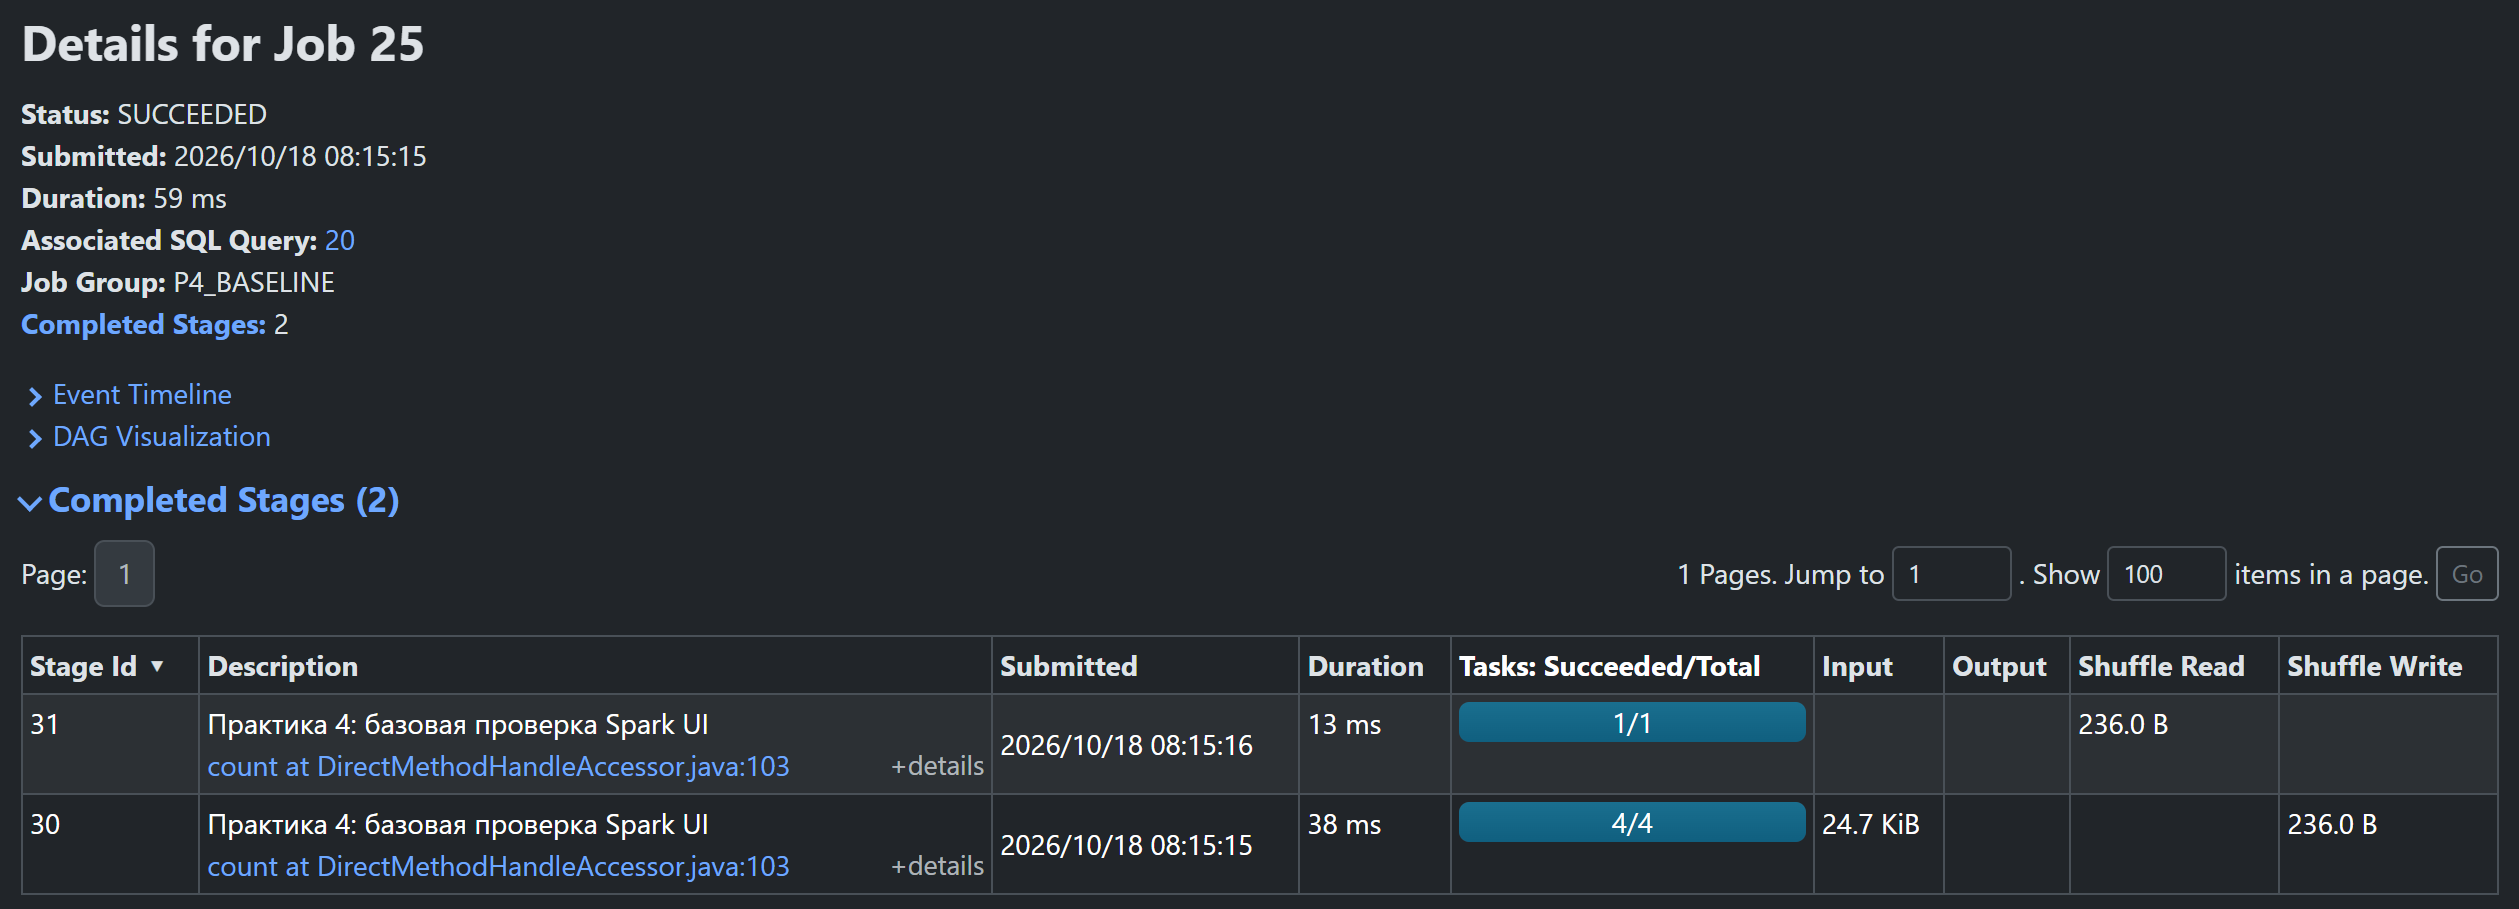

In [7]:
sc.setJobGroup("P4_BASELINE", "Практика 4: базовая проверка Spark UI", interruptOnCancel=True)
_ = items.count()
baseline = ui_summary("P4_BASELINE")

Группа P4_BASELINE: Jobs = 1, Stages = 2


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,30,COMPLETE,4,0.02,0.2,0.0,count at DirectMethodHandleAccessor.java:103
1,31,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103


**Вывод:** простой `count()` по order_items создал 1 Job из 2 Stages. В первой стадии 4 Tasks: по числу партиций Parquet-файла order_items,
во второй 1 Task, которая складывает частичные счётчики (между стадиями небольшой обмен  0.2Кб)

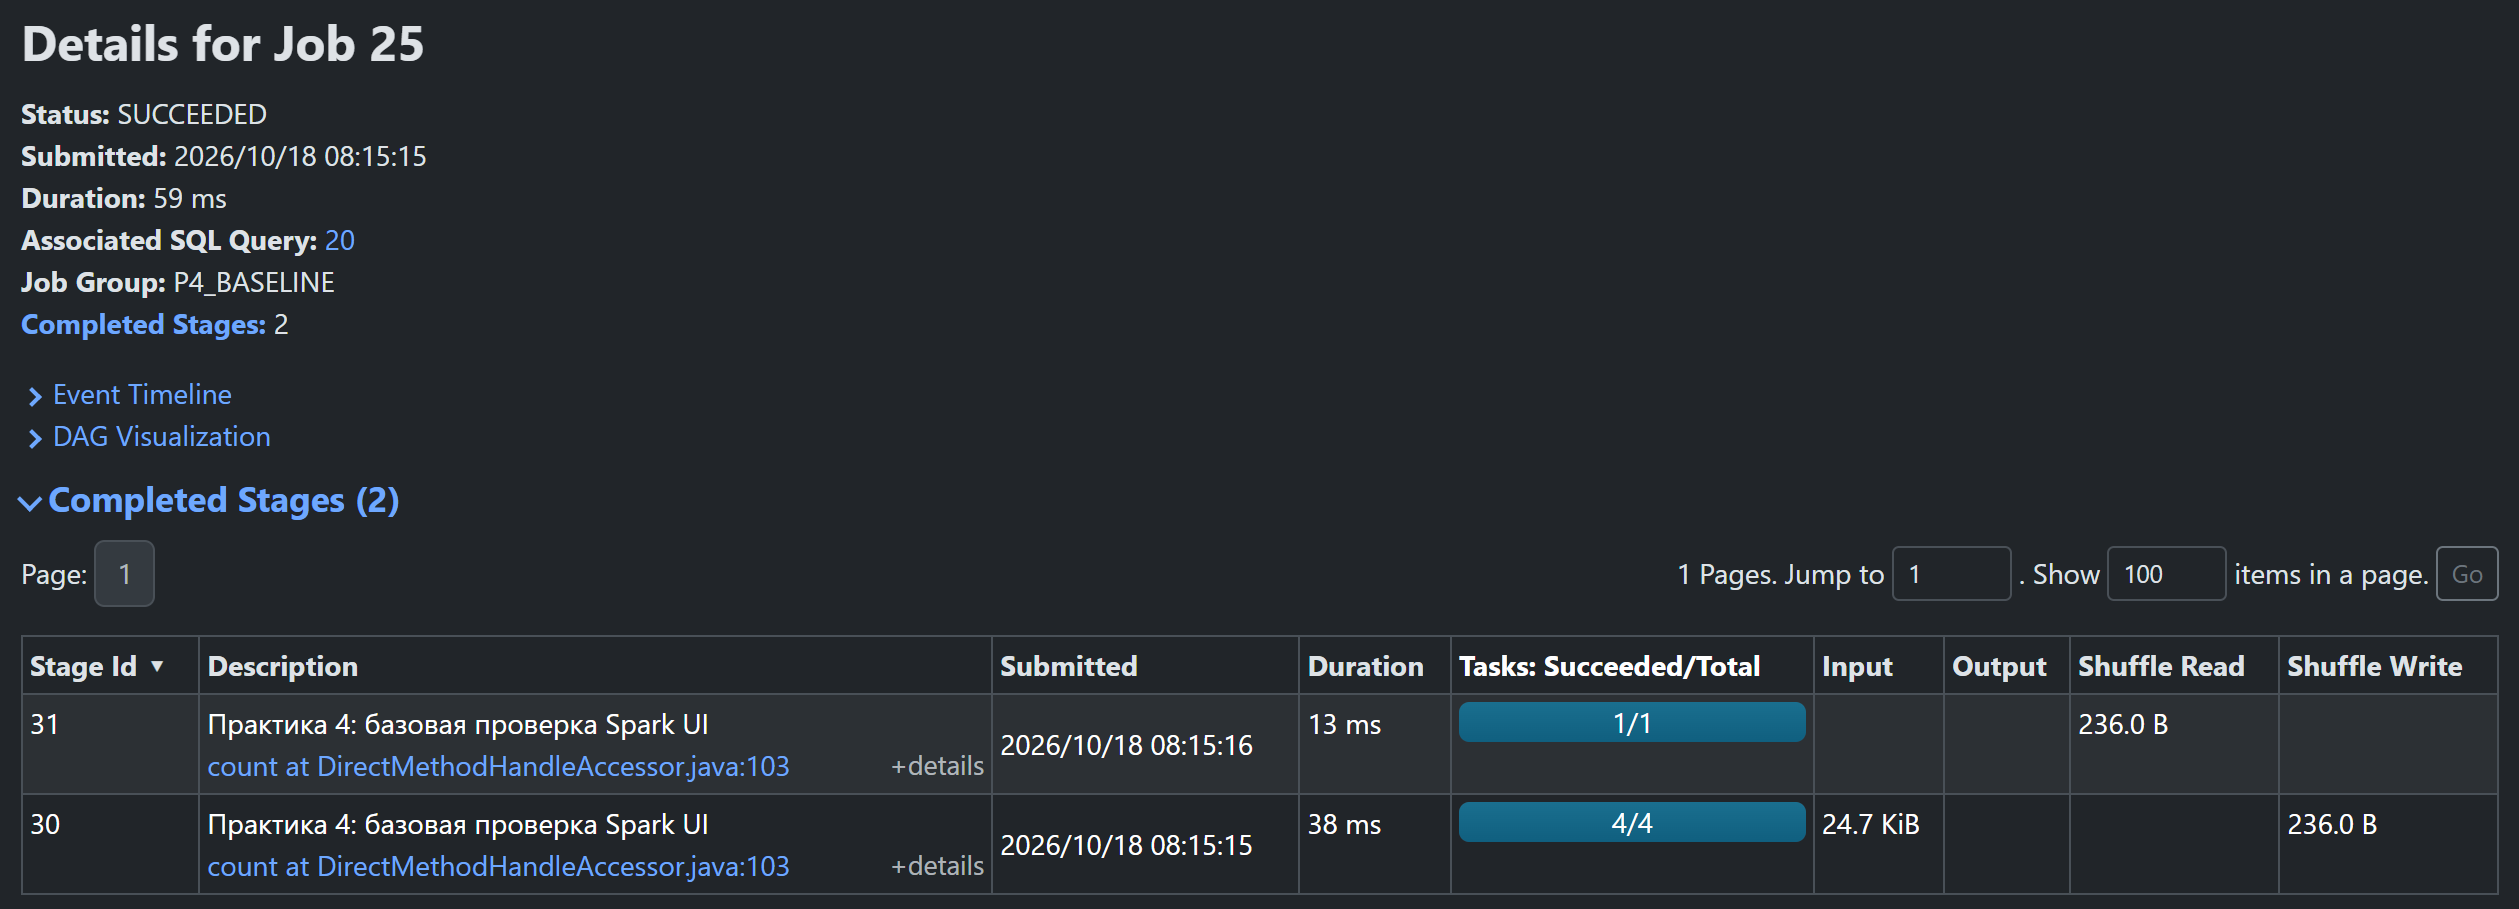

## 5. Ленивые вычисления

### 5.1. Цепочка transformations без Action
`select()`, `filter()` и `withColumn()` только описывают преобразование. Число Jobs в группе `P4_LAZY` проверяется программно
до и после действия.

In [8]:
sc.setJobGroup("P4_LAZY", "Lazy evaluation", interruptOnCancel=True)
t0 = perf_counter()
geo_prepared = (
    geo
    .select("geolocation_zip_code_prefix", "geolocation_state", "geolocation_lat", "geolocation_lng")
    .filter(F.col("geolocation_state").isNotNull())
    .withColumn("abs_lat", F.abs(F.col("geolocation_lat")))
)
t_build = perf_counter() - t0
print(type(geo_prepared).__name__)
print(f"Построение цепочки: {t_build * 1000:.1f} мс")
print("Jobs в группе P4_LAZY до Action:", jobs_in_group("P4_LAZY"))

DataFrame
Построение цепочки: 76.5 мс
Jobs в группе P4_LAZY до Action: 0


### 5.2. Action как момент запуска вычисления

In [9]:
t0 = perf_counter()
n = geo_prepared.count()
elapsed = perf_counter() - t0
print("Rows:", n)
print(f"Elapsed: {elapsed:.3f} s")
print("Jobs в группе P4_LAZY после Action:", jobs_in_group("P4_LAZY"))
lazy_info = ui_summary("P4_LAZY")

Rows: 1000163
Elapsed: 0.575 s
Jobs в группе P4_LAZY после Action: 1
Группа P4_LAZY: Jobs = 1, Stages = 2


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,32,COMPLETE,16,0.16,0.9,0.0,count at DirectMethodHandleAccessor.java:103
1,33,COMPLETE,1,0.00,0.0,0.9,count at DirectMethodHandleAccessor.java:103


**Вывод:** построение цепочки `select - filter - withColumn` заняло 76.5 мс, и в группе `P4_LAZY` не появилось ни одного Job - Spark только записал план.
`count()` запустил 1 Job (2 Stages: 16 Tasks чтения geolocation и 1 итоговая) и занял 0.575 с. Реальная стоимость обработки миллиона строк появляется только при Action.
Строк осталось 1 000 163: пустых значений `geolocation_state` в данных нет.

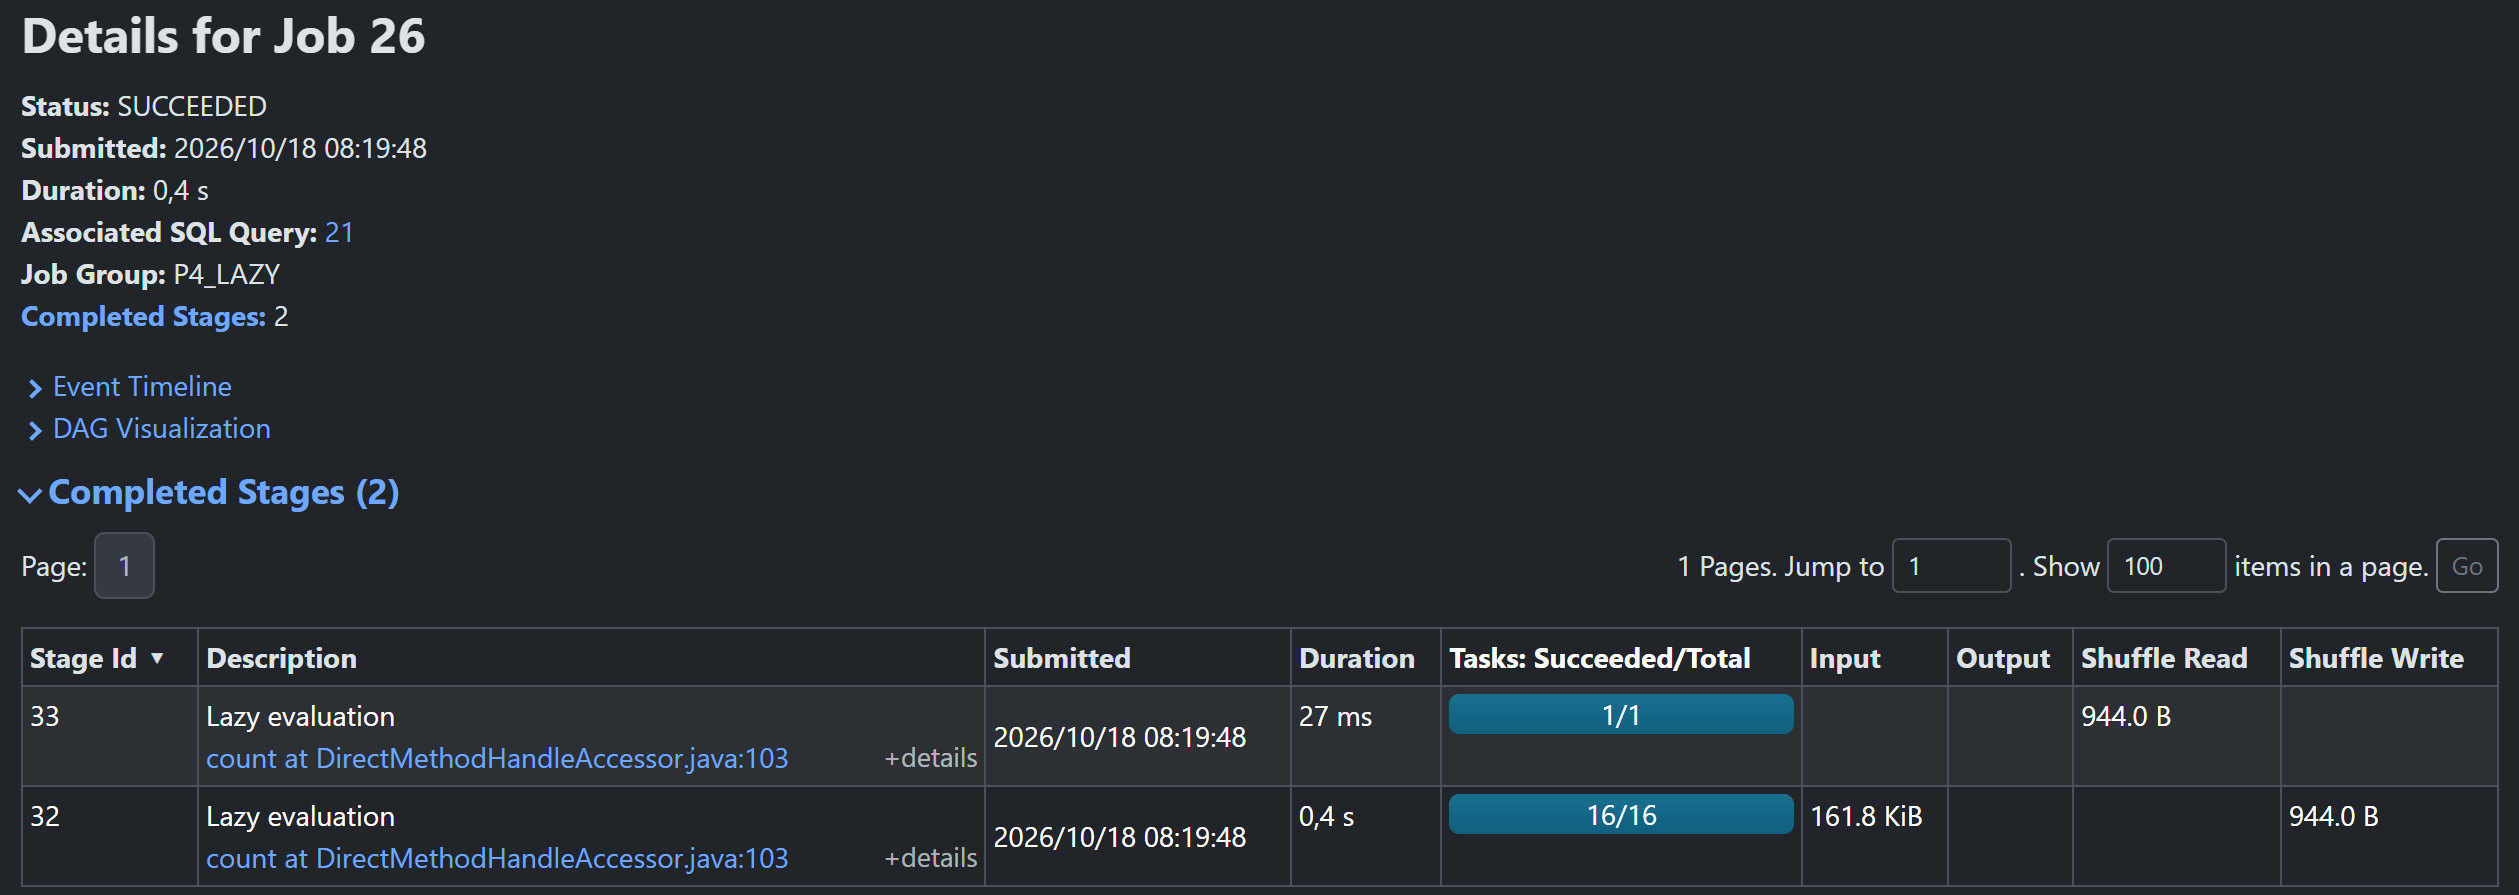

## 6. Партиции и параллелизм

### 6.1. Число партиций и распределение строк
`spark_partition_id()` возвращает номер партиции для каждой строки. Диагностическая группировка выполняется отдельным Job

In [10]:
sc.setJobGroup("P4_PARTITIONS", "Партиции geolocation", interruptOnCancel=True)
print("Input partitions:", geo.rdd.getNumPartitions())
print("Default parallelism:", sc.defaultParallelism)
partition_profile(geo).show(100, truncate=False)

Input partitions: 16
Default parallelism: 20
+---+-----+
|pid|count|
+---+-----+
|0  |63727|
|1  |62834|
|2  |64015|
|3  |63035|
|4  |63121|
|5  |62363|
|6  |62677|
|7  |62580|
|8  |64612|
|9  |61012|
|10 |62301|
|11 |54211|
|12 |61517|
|13 |65521|
|14 |66154|
|15 |60483|
+---+-----+



### 6.2. Перекос ключа `geolocation_state`

In [11]:
total_geo = geo.count()
state_counts = (
    geo.groupBy("geolocation_state").count()
    .withColumn("share_pct", F.round(F.col("count") / total_geo * 100, 2))
    .orderBy(F.desc("count"))
)
state_counts.show(5, truncate=False)
print("Всего штатов:", state_counts.count())

+-----------------+------+---------+
|geolocation_state|count |share_pct|
+-----------------+------+---------+
|SP               |404268|40.42    |
|MG               |126336|12.63    |
|RJ               |121169|12.11    |
|RS               |61851 |6.18     |
|PR               |57859 |5.78     |
+-----------------+------+---------+
only showing top 5 rows
Всего штатов: 27


**Вывод:** geolocation читается в 16 партициях (при 20 логических потоках CPU), размеры варьиюруются от 54 211 до 66 154 строк;
в опыте 5.2 первая стадия тоже имела 16 Tasks. Распределение по ключу сильно перекошено: из 27 штатов на SP приходится 40.42% строк,
на MG и RJ - ещё по 12%. Это свойство данных: при группировке по штату все строки SP окажутся в одной партиции.

## 7. Сравнение `repartition()` и `coalesce()`

### 7.1. Контролируемое уменьшение партиций
`repartition(16, "geolocation_state")` хэширует строки по штату и создаёт перекошенную раскладку. Затем её уменьшают до 4 партиций двумя способами.

In [12]:
skewed16 = geo.repartition(16, "geolocation_state")
repart4 = skewed16.repartition(4)
coal4 = skewed16.coalesce(4)
print("skewed16:", skewed16.rdd.getNumPartitions())
print("repart4:", repart4.rdd.getNumPartitions())
print("coal4:", coal4.rdd.getNumPartitions())

skewed16: 16
repart4: 4
coal4: 4


### 7.2. Физические планы

In [13]:
print("=== repartition(4) ===")
repart4.explain("formatted")
print("=== coalesce(4) ===")
coal4.explain("formatted")

=== repartition(4) ===
== Physical Plan ==
Exchange (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [6]: [geolocation_id#141, geolocation_zip_code_prefix#142, geolocation_lat#143, geolocation_lng#144, geolocation_city#145, geolocation_state#146]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/geolocation]
ReadSchema: struct<geolocation_id:int,geolocation_zip_code_prefix:int,geolocation_lat:double,geolocation_lng:double,geolocation_city:string,geolocation_state:string>

(2) ColumnarToRow [codegen id : 1]
Input [6]: [geolocation_id#141, geolocation_zip_code_prefix#142, geolocation_lat#143, geolocation_lng#144, geolocation_city#145, geolocation_state#146]

(3) Exchange
Input [6]: [geolocation_id#141, geolocation_zip_code_prefix#142, geolocation_lat#143, geolocation_lng#144, geolocation_city#145, geolocation_state#146]
Arguments: RoundRobinPartitioning(4), REPARTITION_BY_NUM, [plan_id=591]


=== coalesce(4) ===
== Phy

### 7.3. Размеры выходных партиций

In [14]:
sc.setJobGroup("P4_REPART", "repartition(4) после skewed16", interruptOnCancel=True)
print("repartition(4)"); partition_profile(repart4).show()
repart_info = ui_summary("P4_REPART", show=False)

sc.setJobGroup("P4_COALESCE", "coalesce(4) после skewed16", interruptOnCancel=True)
print("coalesce(4)"); partition_profile(coal4).show()
coal_info = ui_summary("P4_COALESCE", show=False)

sc.setJobGroup("P4_PARTITIONS", "Профили партиций", interruptOnCancel=True)
table4 = pd.DataFrame([profile_stats(skewed16, "skewed16 (исходная)"),
                       profile_stats(repart4, "repartition(4)"),
                       profile_stats(coal4, "coalesce(4)")])
table4

repartition(4)
+---+------+
|pid| count|
+---+------+
|  0|250040|
|  1|250041|
|  2|250041|
|  3|250041|
+---+------+

coalesce(4)
+---+------+
|pid| count|
+---+------+
|  0|195064|
|  1|626485|
|  2| 90152|
|  3| 88462|
+---+------+



,Вариант,непустых партиций,min rows,max rows,mean rows,max / mean
0,skewed16 (исходная),12,1301,466119,83346.9,5.59
1,repartition(4),4,250040,250041,250040.8,1.00
2,coalesce(4),4,88462,626485,250040.8,2.51


In [15]:
JOURNAL.append(journal_row("repartition(4)", repart_info, "полный shuffle: Exchange перед финальной стадией"))
JOURNAL.append(journal_row("coalesce(4)", coal_info, "объединение партиций без полного shuffle"))
pd.DataFrame(JOURNAL)

,Эксперимент,Jobs,Stages (выполнено / пропущено),Tasks по стадиям,"Shuffle Write, KiB","Shuffle Read, KiB",Что подтверждает UI
0,repartition(4),1,4 / 0,16 - 16 - 4 - 8,173.8,173.8,полный shuffle: Exchange перед финальной стадией
1,coalesce(4),1,3 / 0,16 - 4 - 8,153.1,153.1,объединение партиций без полного shuffle


**Вывод:** оба варианта дали 4 партиции и 1 000 163 строки, но устроены по-разному.
- **Исходная раскладка.** Хэширование по штату (`skewed16`) заполнило только 12 из 16 партиций, размеры - от 1 301 до 466 119 строк (max/mean = 5,59).
- **repartition(4).** В плане `Exchange RoundRobinPartitioning(4)` - полный shuffle, партиции выровнены: 250 040–250 041 строк (max/mean = 1,00).
- **coalesce(4).** В плане сохранился `Exchange hashpartitioning(geolocation_state, 16)`, а поверх него - оператор `Coalesce 4`:
  соседние партиции склеены без нового shuffle, и перекос остался - от 88 462 до 626 485 строк (max/mean = 2,51).

coalesce - дешёвая операция для частого случая «партиций слишком много, а данные распределены нормально»; repartition - дорогая, для случая «данные распределены плохо, и это мешает»

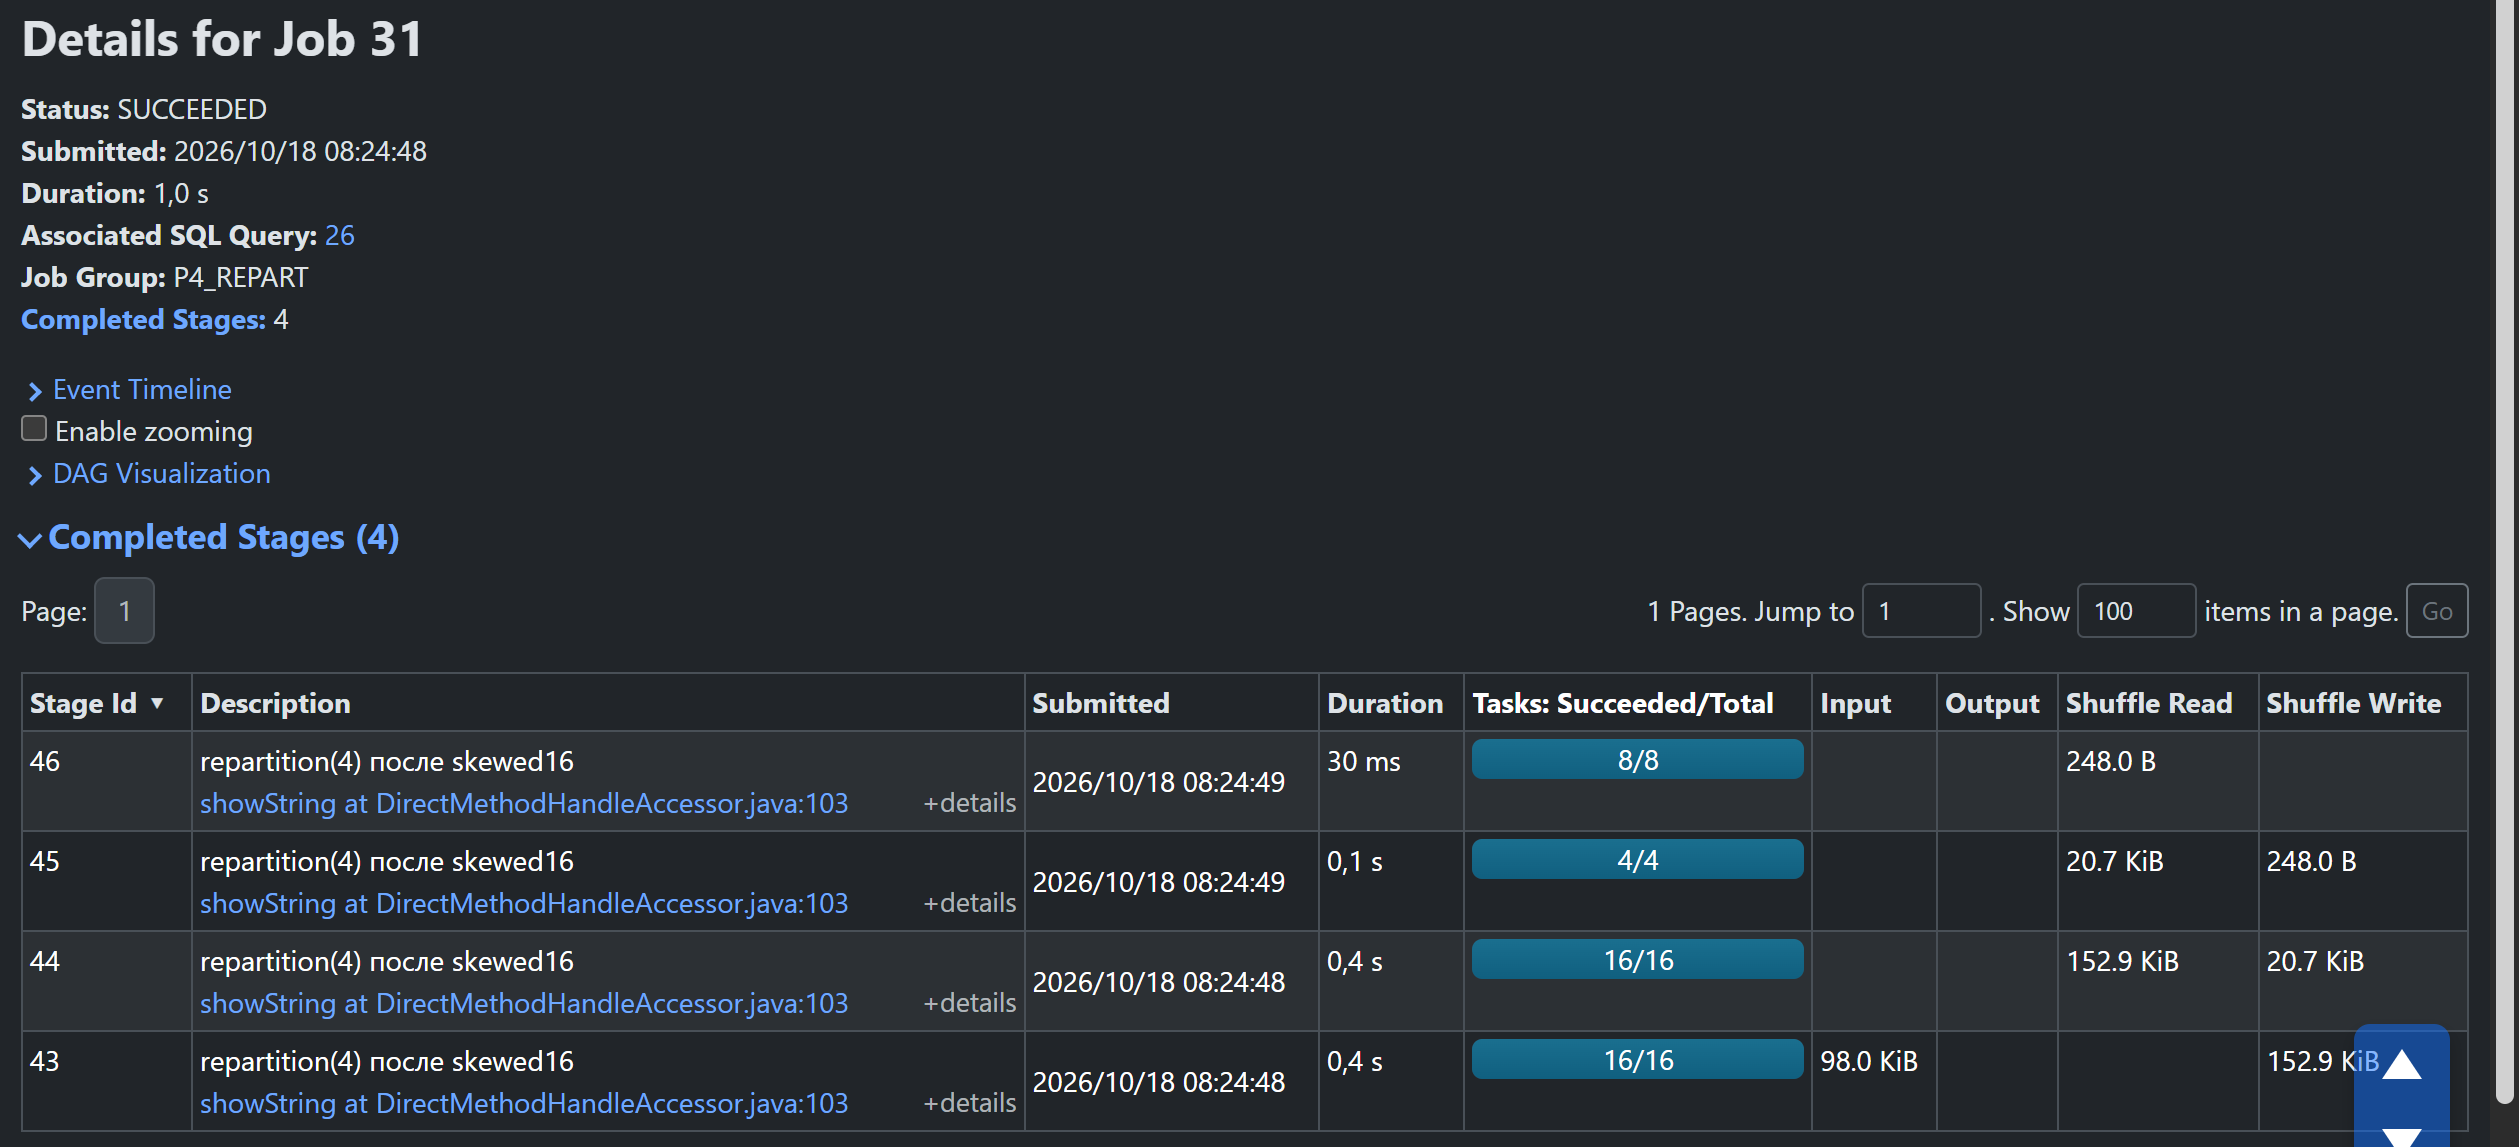

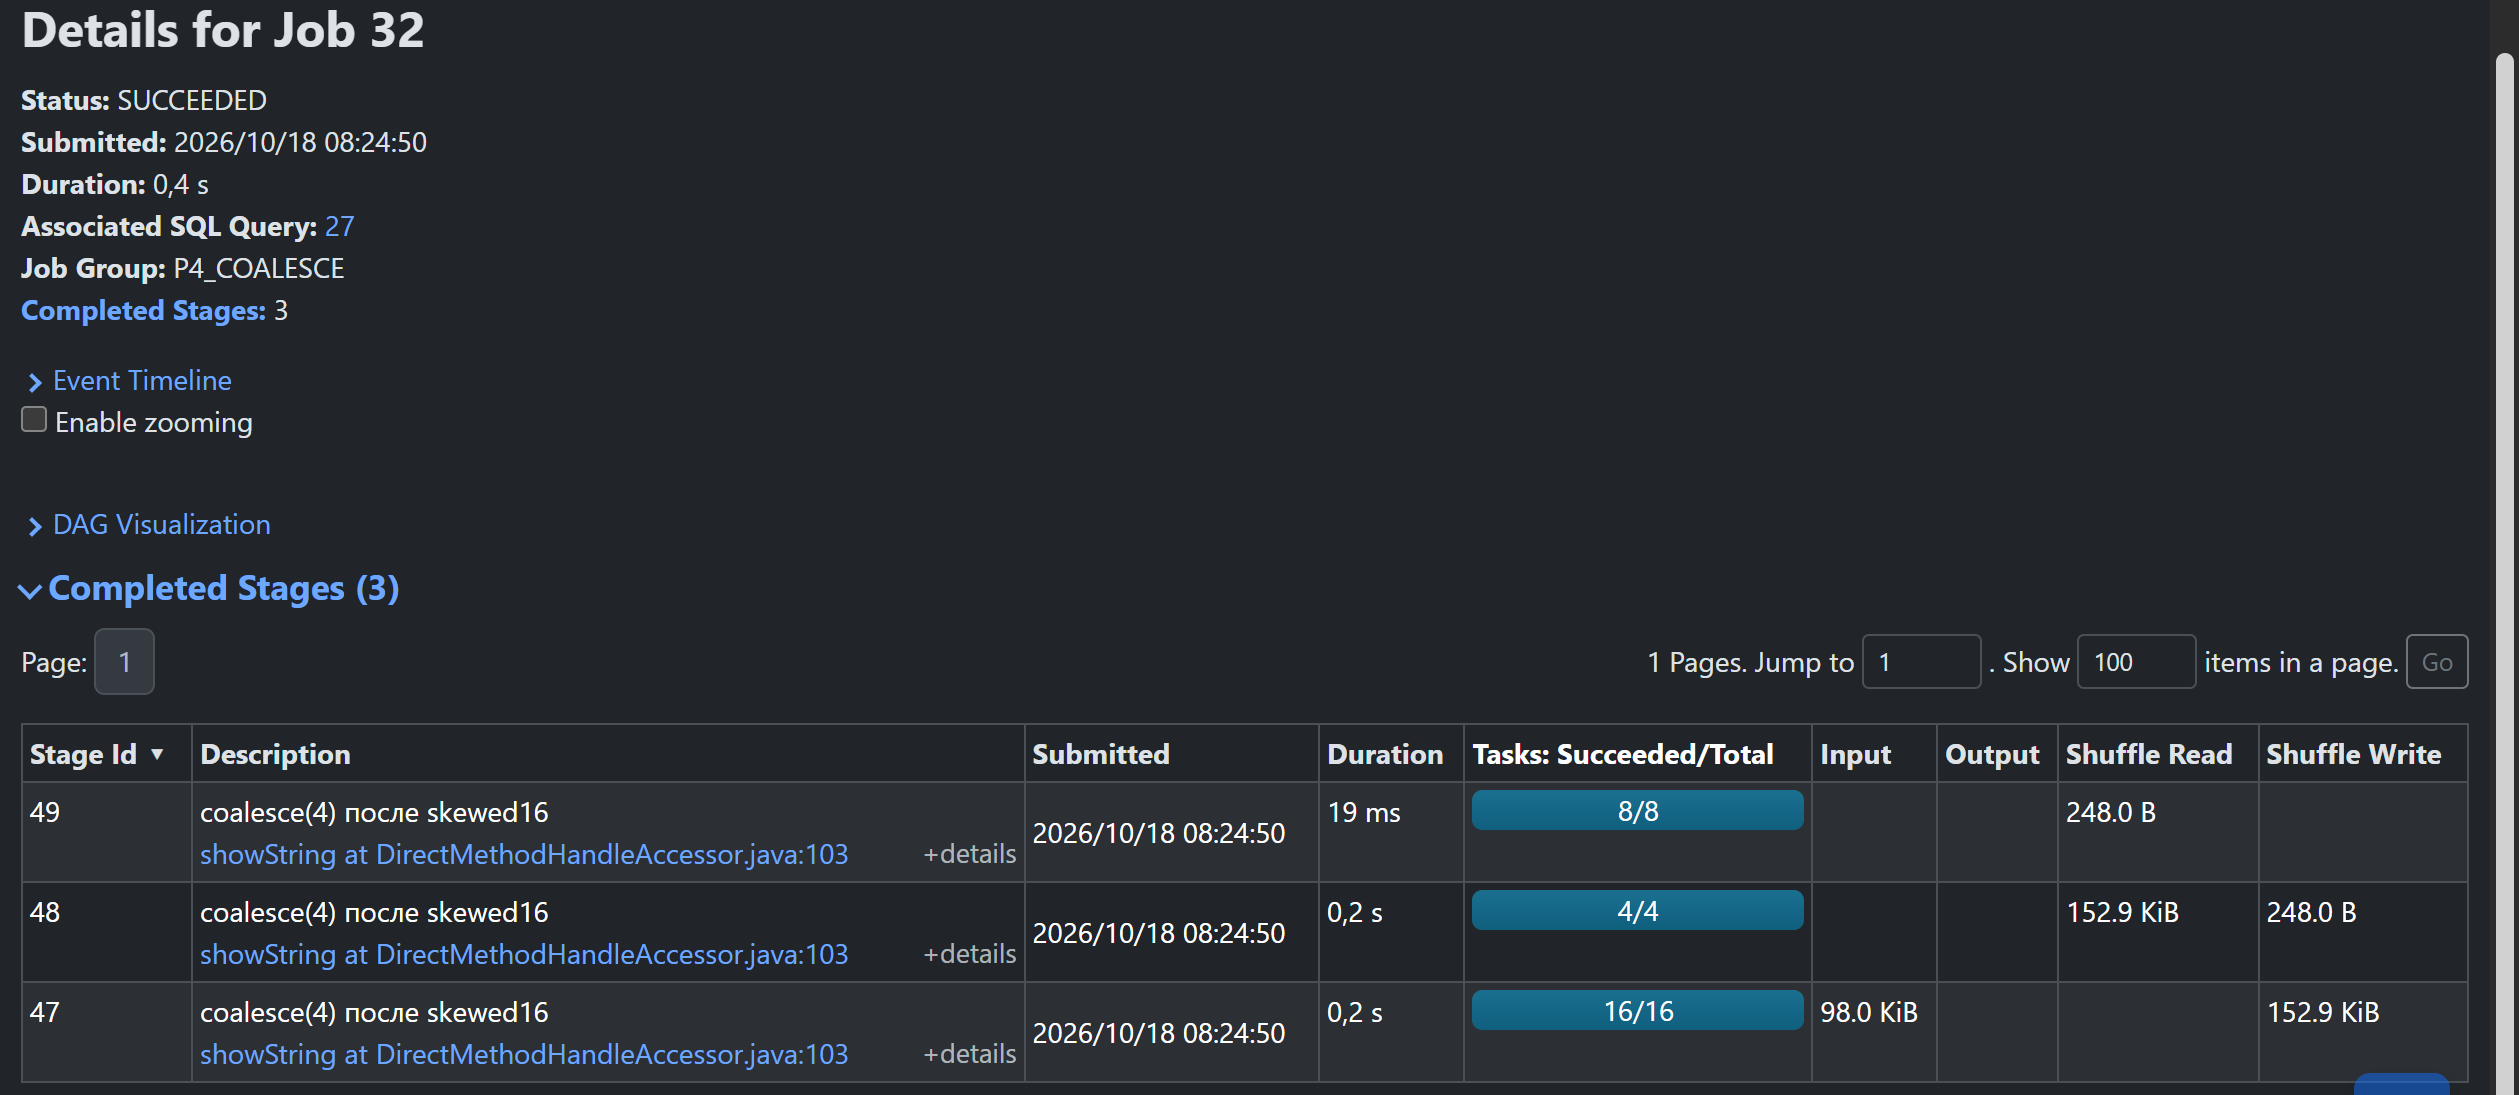

## 8. Shuffle на примере `groupBy()`

### 8.1. Агрегация `order_items` по продавцам
Spark сначала агрегирует каждую партицию локально (`partial_*`), затем перемешивает по ключу (`Exchange hashpartitioning(seller_id, 8)`)
и выполняет финальную агрегацию.

In [16]:
sc.setJobGroup("P4_GROUPBY", "Shuffle: groupBy seller_id", interruptOnCancel=True)
seller_stats = (
    items.groupBy("seller_id")
    .agg(F.count("*").alias("items"),
         F.round(F.sum("price"), 2).alias("revenue"),
         F.round(F.avg("price"), 2).alias("avg_price"))
    .orderBy(F.desc("revenue"))
)
seller_stats.show(5, truncate=False)
groupby_info = ui_summary("P4_GROUPBY")
JOURNAL.append(journal_row("groupBy seller_id", groupby_info, "граница стадий на Exchange hashpartitioning(seller_id, 8)"))

+--------------------------------+-----+---------+---------+
|seller_id                       |items|revenue  |avg_price|
+--------------------------------+-----+---------+---------+
|4869f7a5dfa277a7dca6462dcf3b52b2|1156 |229472.63|198.51   |
|53243585a1d6dc2643021fd1853d8905|410  |222776.05|543.36   |
|4a3ca9315b744ce9f8e9374361493884|1987 |200472.92|100.89   |
|fa1c13f2614d7b5c4749cbc52fecda94|586  |194042.03|331.13   |
|7c67e1448b00f6e969d365cea6b010ab|1364 |187923.89|137.77   |
+--------------------------------+-----+---------+---------+
only showing top 5 rows
Группа P4_GROUPBY: Jobs = 1, Stages = 2


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,73,COMPLETE,4,0.02,438.6,0.0,showString at DirectMethodHandleAccessor.java:103
1,74,COMPLETE,8,0.00,0.0,438.6,showString at DirectMethodHandleAccessor.java:103


### 8.2. Физический план `groupBy()`

In [18]:
seller_stats.explain("formatted")

== Physical Plan ==
* Sort (7)
+- Exchange (6)
   +- * HashAggregate (5)
      +- Exchange (4)
         +- * HashAggregate (3)
            +- * ColumnarToRow (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [2]: [seller_id#150, price#152]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/order_items]
ReadSchema: struct<seller_id:string,price:double>

(2) ColumnarToRow [codegen id : 1]
Input [2]: [seller_id#150, price#152]

(3) HashAggregate [codegen id : 1]
Input [2]: [seller_id#150, price#152]
Keys [1]: [seller_id#150]
Functions [3]: [partial_count(1), partial_sum(price#152), partial_avg(price#152)]
Aggregate Attributes [4]: [count#352L, sum#353, sum#354, count#355L]
Results [5]: [seller_id#150, count#356L, sum#357, sum#358, count#359L]

(4) Exchange
Input [5]: [seller_id#150, count#356L, sum#357, sum#358, count#359L]
Arguments: hashpartitioning(seller_id#150, 8), ENSURE_REQUIREMENTS, [plan_id=1090]

(5) HashAggregate [codegen

**Вывод:** агрегация по seller_id выполнилась в 1 Job из 2 Stages: 4 Tasks частичной агрегации записали 438.6 Кб shuffle,
8 Tasks финальной агрегации (по `spark.sql.shuffle.partitions = 8`) прочитали те же 438.6 Кб.
В плане видны обе фазы: `HashAggregate` с `partial_count / partial_sum / partial_avg` - `Exchange hashpartitioning(seller_id, 8)` - финальный `HashAggregate`;
сортировка `orderBy` добавляет ещё `Exchange rangepartitioning(revenue, 8)` и `Sort`.
Лидер по выручке - продавец 4869f7a5 (1156 позиций, 229472,63), результат совпадает с таблицей из методички

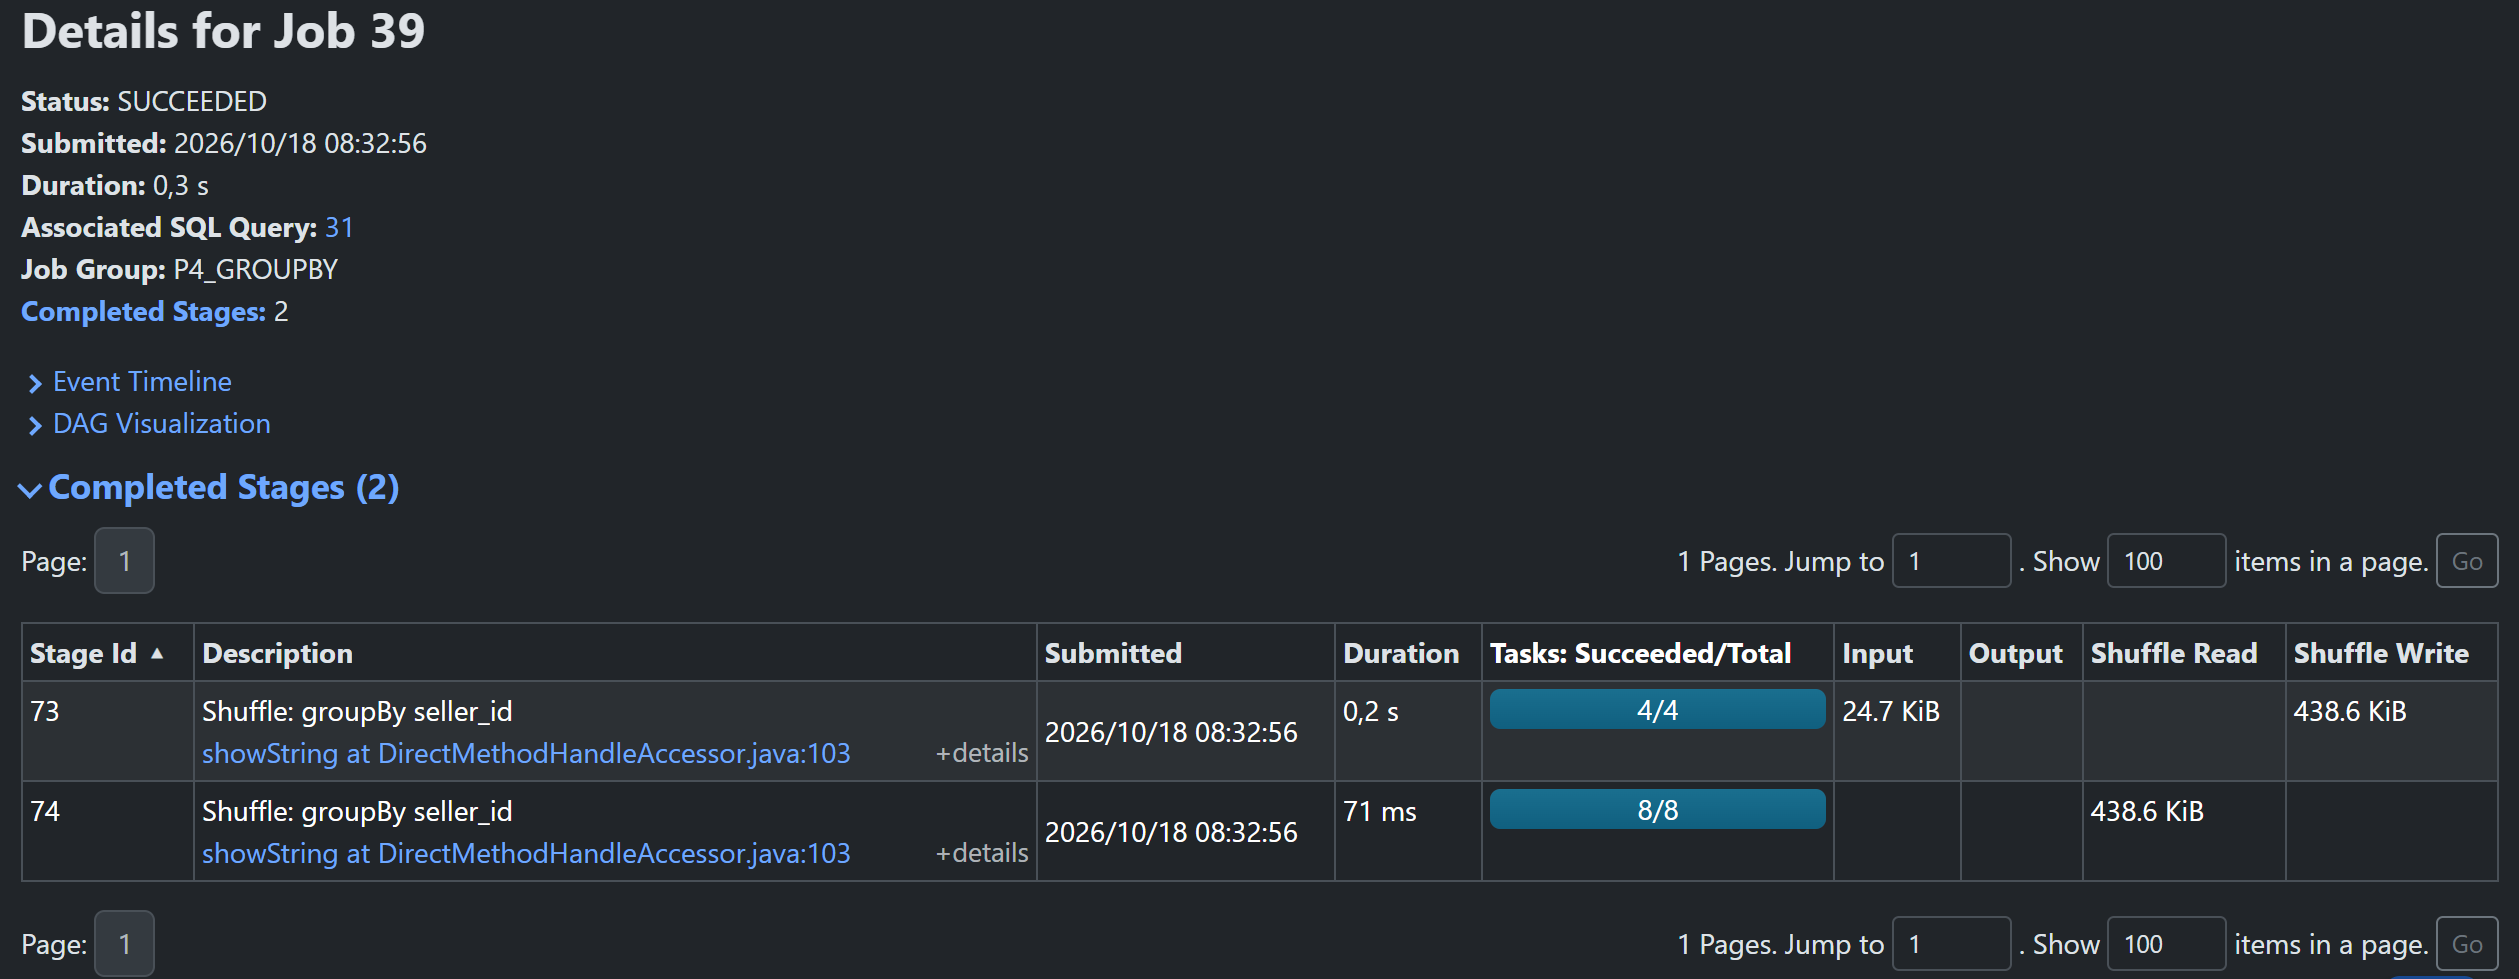

## 9. Чтение плана через `explain("formatted")`

In [19]:
plan_demo = (
    items
    .filter(F.col("price") >= 100)
    .select("seller_id", "price", "freight_value")
    .withColumn("gross", F.col("price") + F.col("freight_value"))
    .groupBy("seller_id")
    .agg(F.round(F.sum("gross"), 2).alias("gross_sum"))
)
plan_demo.explain("formatted")

== Physical Plan ==
* HashAggregate (7)
+- Exchange (6)
   +- * HashAggregate (5)
      +- * Project (4)
         +- * Filter (3)
            +- * ColumnarToRow (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [seller_id#150, price#152, freight_value#153]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(price), GreaterThanOrEqual(price,100.0)]
ReadSchema: struct<seller_id:string,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [3]: [seller_id#150, price#152, freight_value#153]

(3) Filter [codegen id : 1]
Input [3]: [seller_id#150, price#152, freight_value#153]
Condition : (isnotnull(price#152) AND (price#152 >= 100.0))

(4) Project [codegen id : 1]
Output [2]: [seller_id#150, (price#152 + freight_value#153) AS gross#381]
Input [3]: [seller_id#150, price#152, freight_value#153]

(5) HashAggregate [codegen id : 1]
Input [2]: [seller_id#150, gross#381]
Keys 

**Вывод:** план читается снизу вверх:
1. **Scan parquet** читает только 3 нужных столбца (seller_id, price, freight_value), а условие `price >= 100` передано в источник (`PushedFilters`), т.к. Parquet хранит данные по столбцам с max/min значениями
2. **Filter** завершает отбор строк, **Project** вычисляет `gross` и отбрасывает ненужные столбцы для уменьшения передаваемых данных
3. **HashAggregate (partial_sum)** сворачивает каждую партицию до одной строки на продавца
4. **Exchange hashpartitioning(seller_id, 8)** перемешивает уже сокращённые частичные суммы по продавцам
5. Финальный **HashAggregate** складывает частичные суммы и округляет результат

## 10. Sort Merge Join и Broadcast Hash Join

Нужно к каждой позиции заказа приписать данные её товара из справочника по product_id. Сложность в том, что данные разбиты на партиции: позиции с товаром X могут лежать в любой из 4 партиций order_items, а сам товар X - где-то в products. Чтобы соединить строку, нужно, чтобы позиция и её товар оказались в одной задаче. Две стратегии добиваются этого по-разному.

### 10.1. Sort Merge Join
Автоматический broadcast выключен, `hint("merge")` явно просит merge-стратегию. В плане ожидаются `Exchange hashpartitioning(product_id, 8)` и `Sort` с обеих сторон

In [20]:
sc.setJobGroup("P4_SMJ", "Sort Merge Join: items x products", interruptOnCancel=True)
smj = items.hint("merge").join(products.hint("merge"), on="product_id", how="inner")
smj.explain("formatted")
t0 = perf_counter()
smj_rows = smj.count()
smj_time = perf_counter() - t0
print("Rows:", smj_rows, f" time: {smj_time:.3f} s")
smj_info = ui_summary("P4_SMJ")

== Physical Plan ==
* Project (12)
+- * SortMergeJoin Inner (11)
   :- * Sort (5)
   :  +- Exchange (4)
   :     +- * Filter (3)
   :        +- * ColumnarToRow (2)
   :           +- Scan parquet  (1)
   +- * Sort (10)
      +- Exchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]

(3) Filter [codegen id : 1]
Input [7]: [order_id

,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,75,COMPLETE,1,0.01,1088.3,0.0,count at DirectMethodHandleAccessor.java:103
1,76,COMPLETE,4,0.04,2744.1,0.0,count at DirectMethodHandleAccessor.java:103
2,77,COMPLETE,8,0.00,0.5,3832.4,count at DirectMethodHandleAccessor.java:103
3,78,COMPLETE,1,0.00,0.0,0.5,count at DirectMethodHandleAccessor.java:103


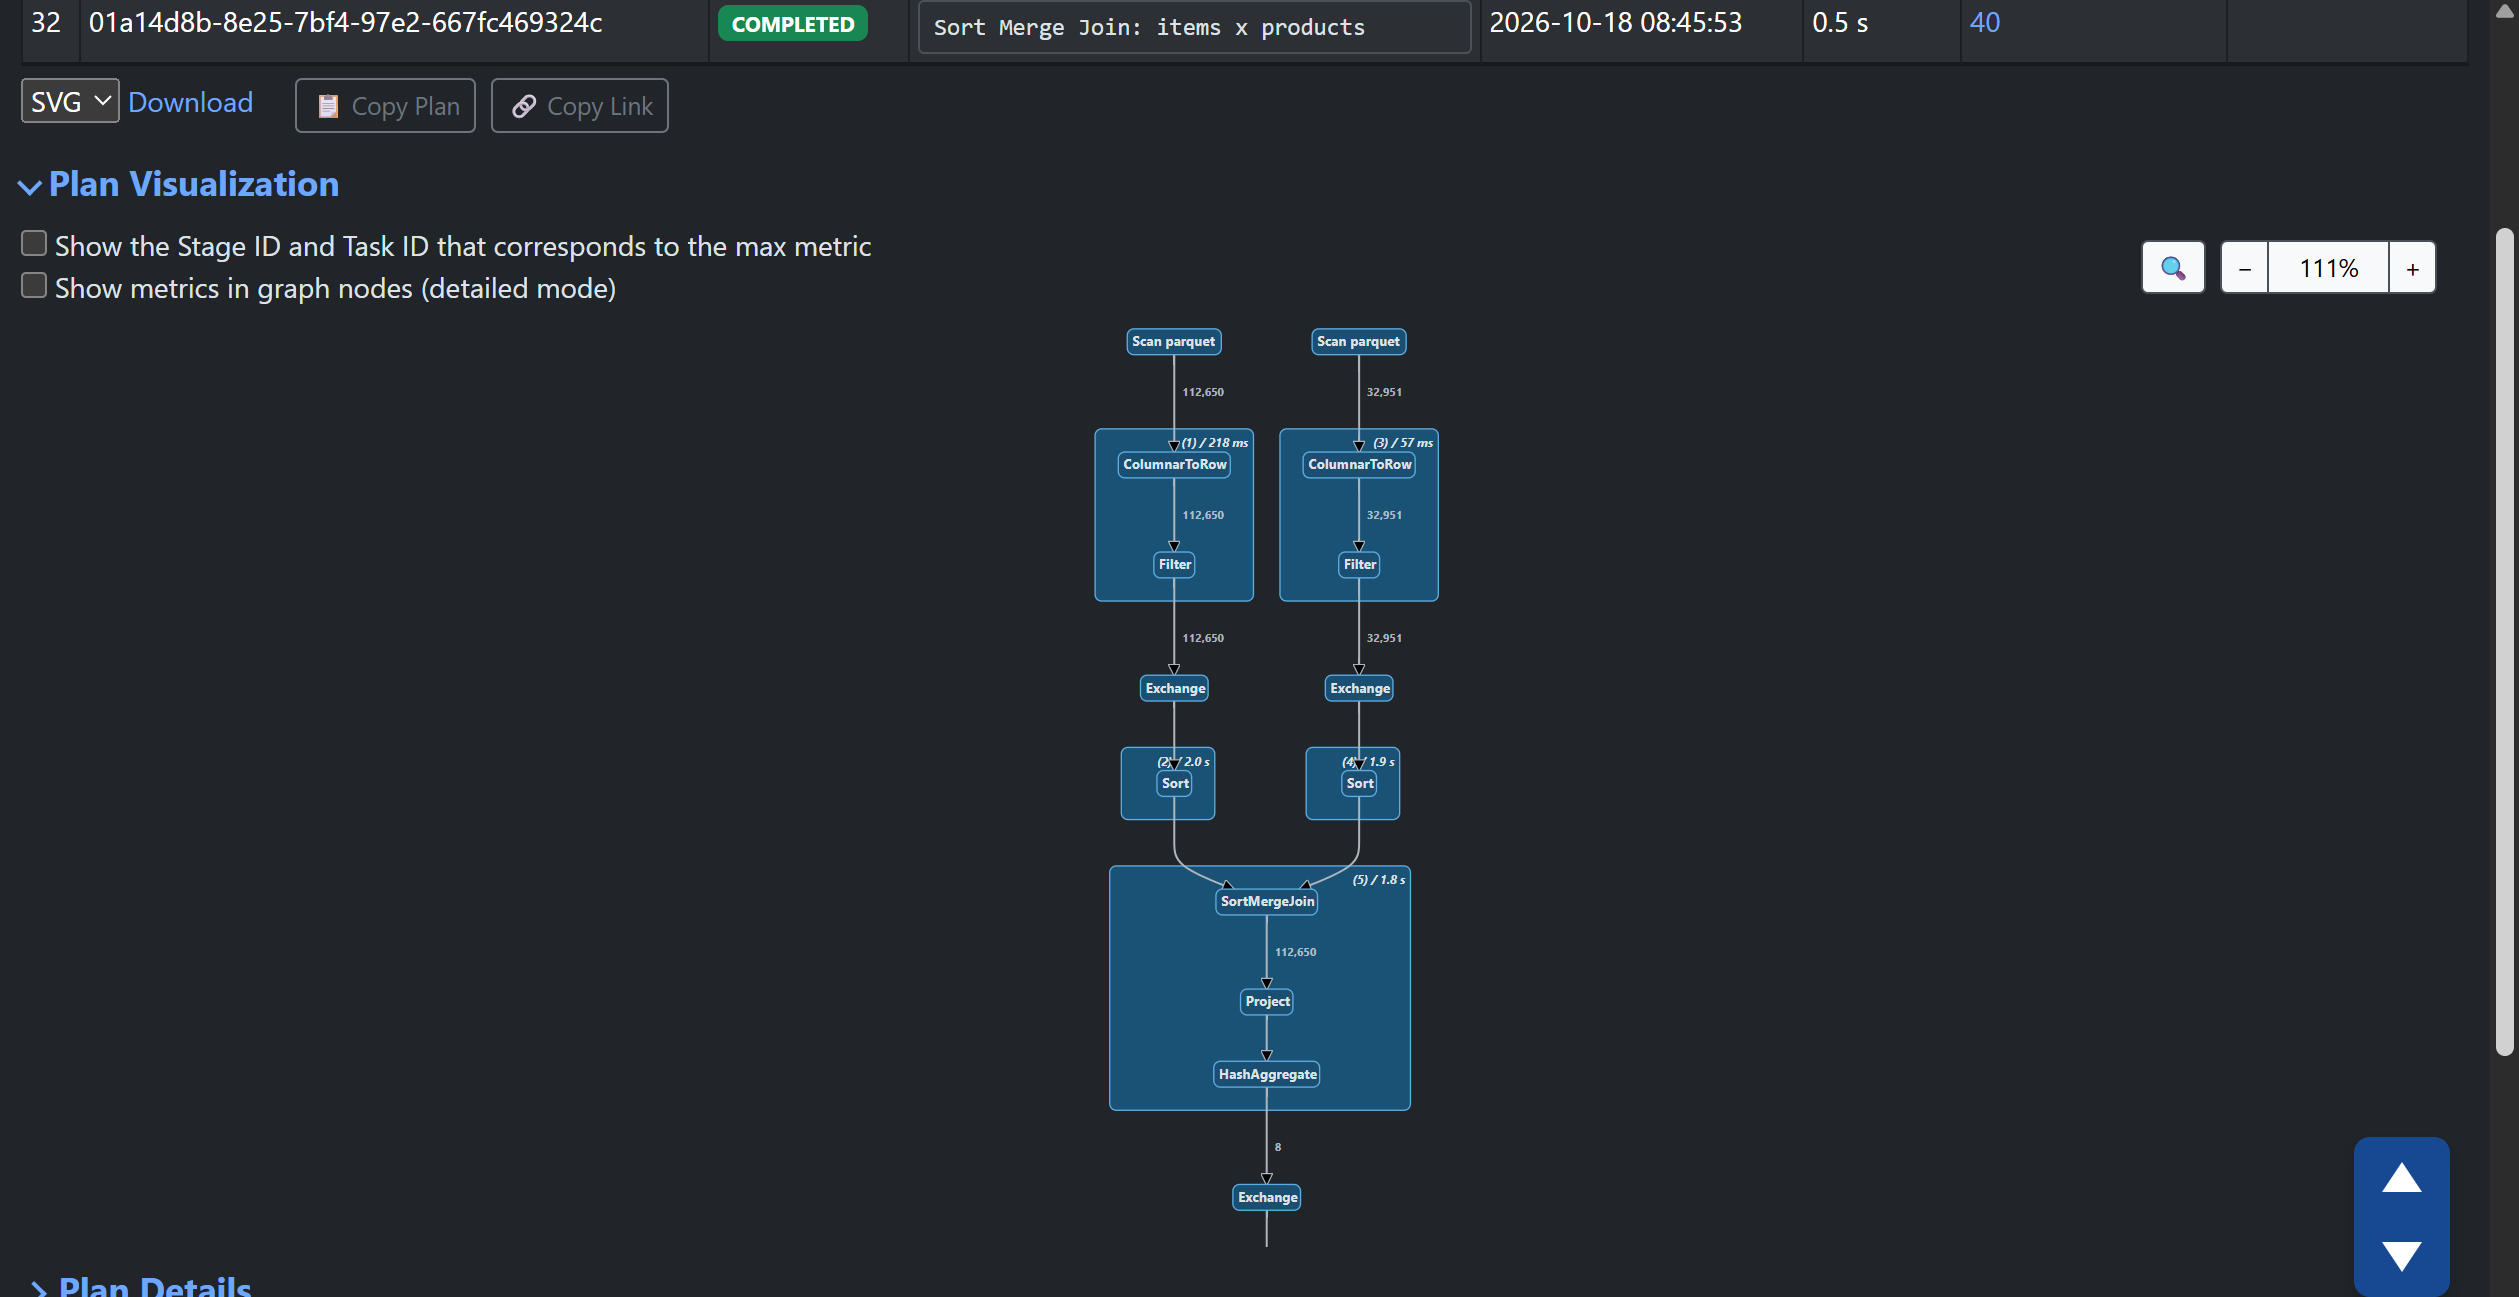

### 10.2. Broadcast Hash Join
`F.broadcast(products)` - явная подсказка отправить `products` целиком в каждую задачу. Смысл запроса тот же, меняется физическая стратегия:
в плане `BroadcastExchange` и `BroadcastHashJoin`, большая сторона не перемешивается.

In [21]:
sc.setJobGroup("P4_BHJ", "Broadcast Hash Join: items x products", interruptOnCancel=True)
bhj = items.join(F.broadcast(products), on="product_id", how="inner")
bhj.explain("formatted")
t0 = perf_counter()
bhj_rows = bhj.count()
bhj_time = perf_counter() - t0
print("Rows:", bhj_rows, f" time: {bhj_time:.3f} s")
bhj_info = ui_summary("P4_BHJ")

== Physical Plan ==
* Project (9)
+- * BroadcastHashJoin Inner BuildRight (8)
   :- * Filter (3)
   :  +- * ColumnarToRow (2)
   :     +- Scan parquet  (1)
   +- BroadcastExchange (7)
      +- * Filter (6)
         +- * ColumnarToRow (5)
            +- Scan parquet  (4)


(1) Scan parquet 
Output [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 2]
Input [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]

(3) Filter [codegen id : 2]
Input [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_

,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,79,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
1,80,COMPLETE,4,0.04,0.2,0.0,count at DirectMethodHandleAccessor.java:103
2,81,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103


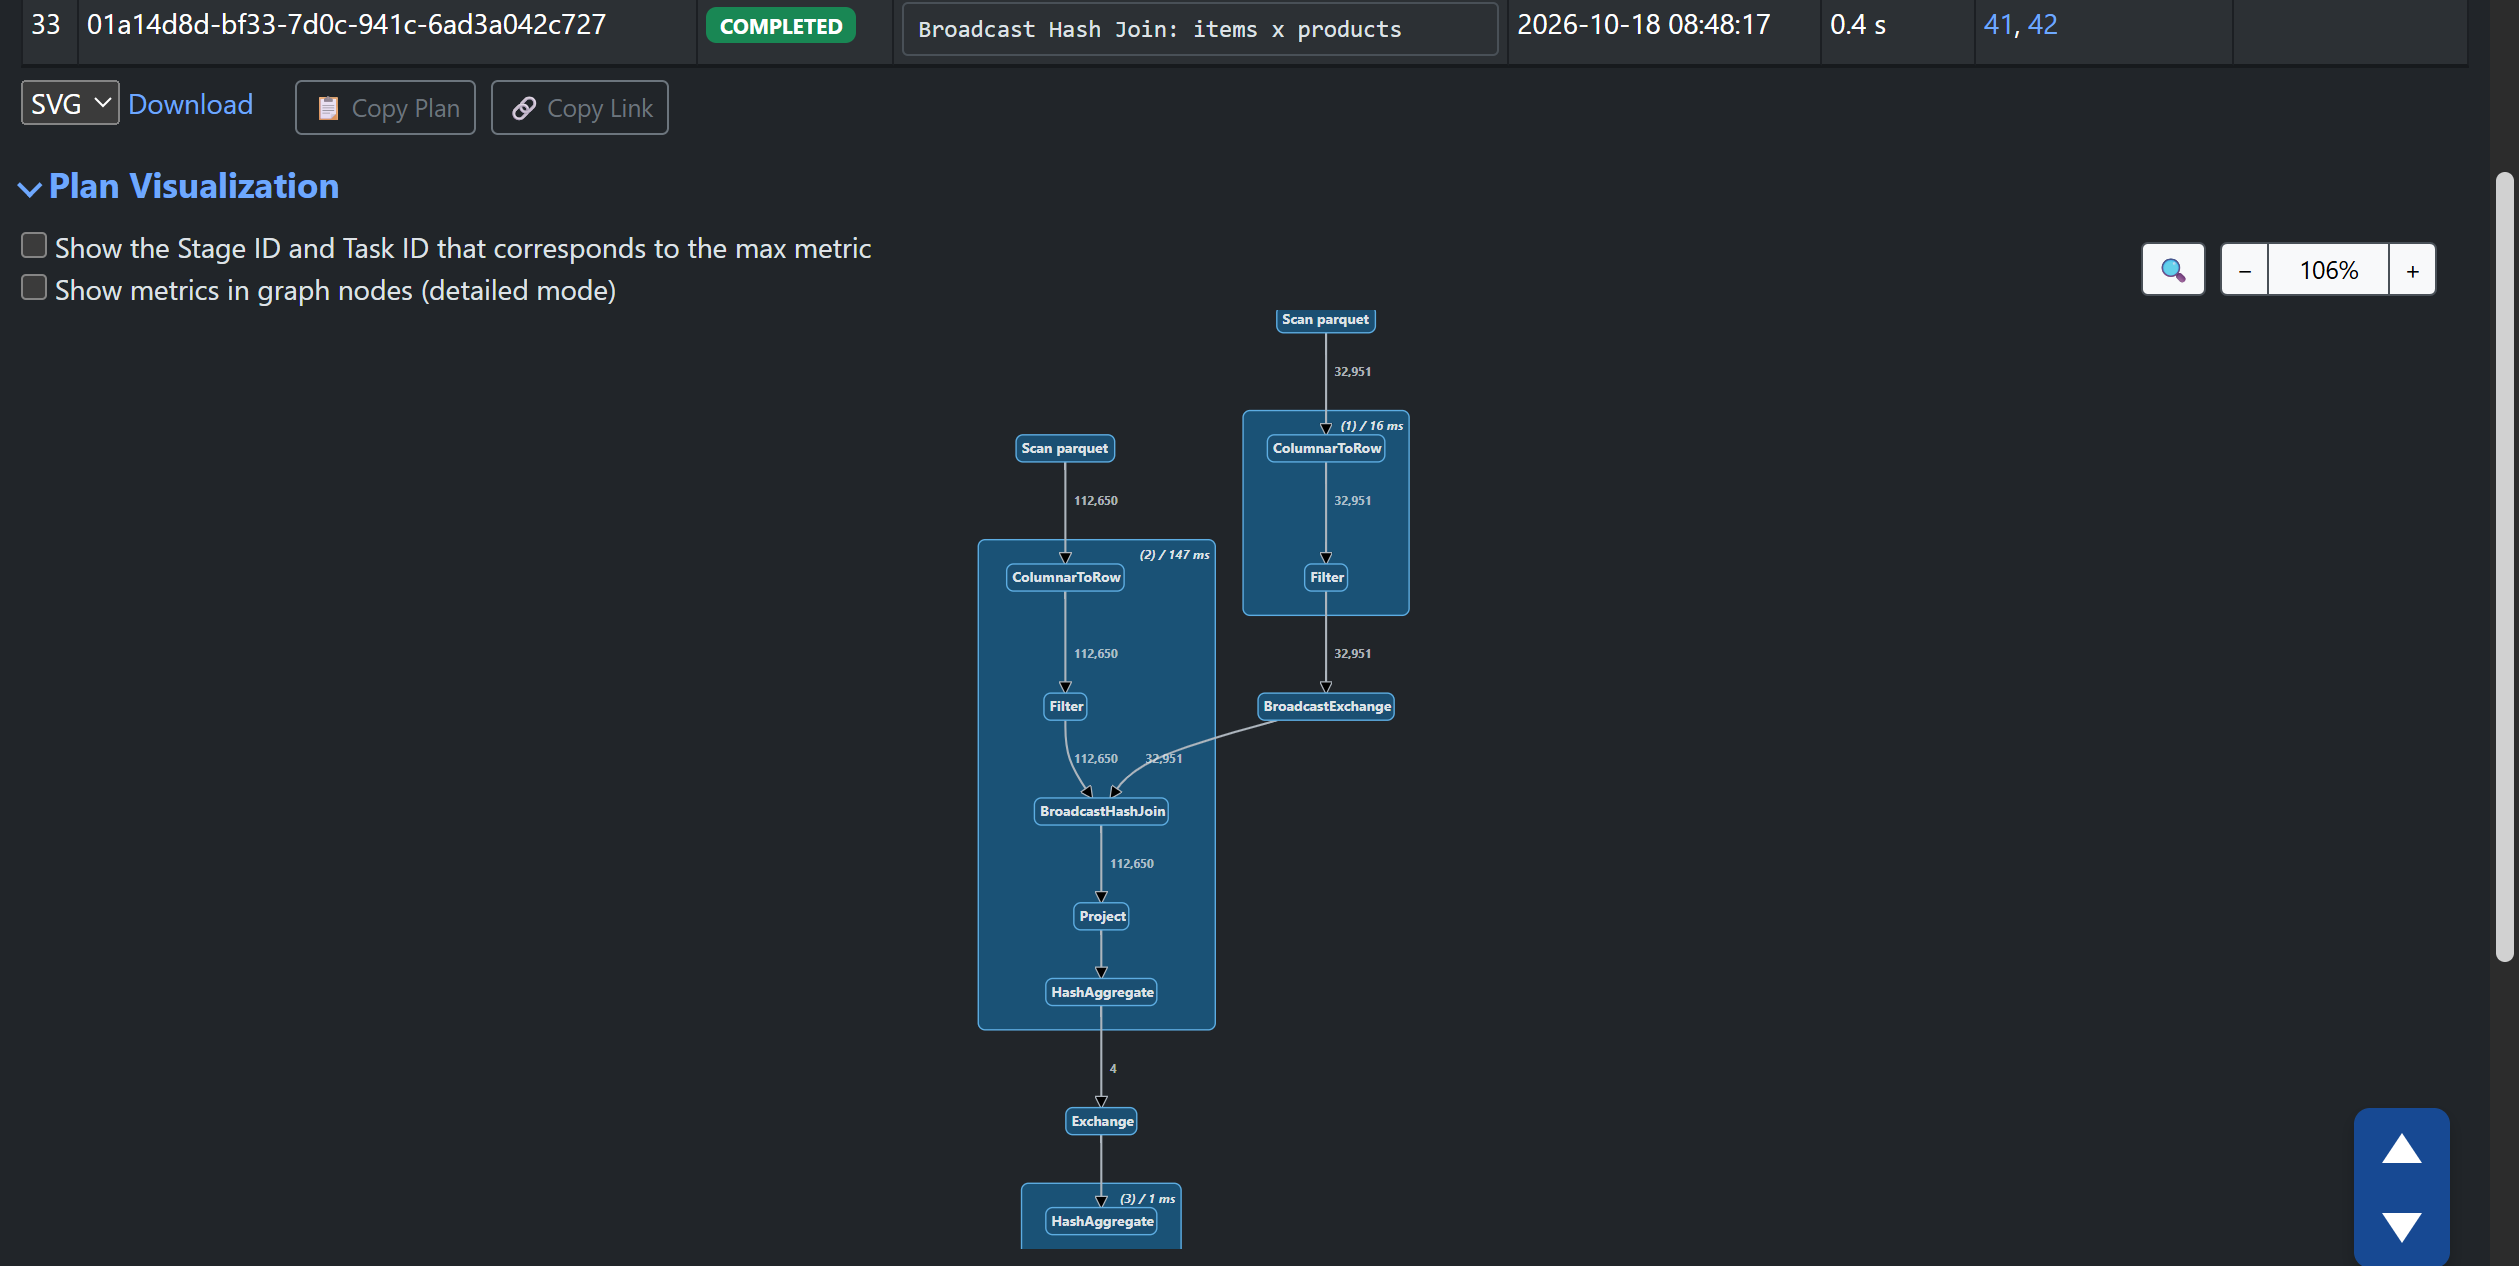

### 10.3. Сравнение JOIN-стратегий

In [23]:
def shuffle_sum(info, col):
    st = info["stages"]
    return round(st.loc[st["status"] != "SKIPPED", col].sum(), 1) if len(st) else 0

table6 = pd.DataFrame({
    "Показатель": ["Строк результата", "Exchange большой стороны", "Shuffle Write / Read, KiB",
                   "Jobs / Stages", "Время, с"],
    "Sort Merge Join": [smj_rows, "есть (hashpartitioning по product_id)",
                        f"{shuffle_sum(smj_info, 'shuffle_write_KiB')} / {shuffle_sum(smj_info, 'shuffle_read_KiB')}",
                        f"{smj_info['jobs']} / {len(smj_info['stages'])}", round(smj_time, 3)],
    "Broadcast Hash Join": [bhj_rows, "нет (products передаётся целиком)",
                            f"{shuffle_sum(bhj_info, 'shuffle_write_KiB')} / {shuffle_sum(bhj_info, 'shuffle_read_KiB')}",
                            f"{bhj_info['jobs']} / {len(bhj_info['stages'])}", round(bhj_time, 3)],
})
JOURNAL.append(journal_row("Sort Merge Join", smj_info, "Exchange + Sort с обеих сторон перед SortMergeJoin"))
JOURNAL.append(journal_row("Broadcast Hash Join", bhj_info, "отдельный Job для broadcast, большая сторона без Exchange"))
table6

,Показатель,Sort Merge Join,Broadcast Hash Join
0,Строк результата,112650,112650
1,Exchange большой стороны,есть (hashpartitioning по product_id),нет (products передаётся целиком)
2,"Shuffle Write / Read, KiB",3832.9 / 3832.9,0.2 / 0.2
3,Jobs / Stages,1 / 4,2 / 3
4,"Время, с",0.533,0.359


**Вывод:** обе стратегии вернули 112 650 строк - запросы логически эквивалентны, различается только физическое выполнение.
- **Sort Merge Join:** 1 Job, 4 Stages. Обе стороны перемешаны по product_id (order_items записал 2 744 KiB, products - 1 088 KiB,
  стадия соединения из 8 Tasks прочитала 3 832 KiB), перед `SortMergeJoin` обе стороны отсортированы. Время 0.533 с.
- **Broadcast Hash Join:** 2 Jobs (отдельный Job из 1 Task собирает products для рассылки), 3 Stages. Shuffle большой стороны нет
  (0,2 KiB - только итоговый count), в плане `BroadcastExchange` и `BroadcastHashJoin BuildRight`. Время 0.359 с.

## 11. `cache()` / `persist()`

### 11.1. Повторно используемый промежуточный DataFrame
`joined`- order_items с категорией товара и штатом продавца; над ним выполняются два независимых действия.
Функции возвращают контрольную сумму, чтобы Spark действительно вычислил агрегаты.

In [24]:
spark.catalog.clearCache()
products_small = products.select("product_id", "product_category_name")
sellers_small = sellers.select("seller_id", "seller_state")
joined = (
    items
    .join(F.broadcast(products_small), "product_id", "left")
    .join(F.broadcast(sellers_small), "seller_id", "left")
    .withColumn("gross_value", F.col("price") + F.col("freight_value"))
)

def action_category(df):
    return (df.groupBy("product_category_name").agg(F.sum("gross_value").alias("gross"))
              .agg(F.sum("gross").alias("checksum")).first()[0])

def action_state(df):
    return (df.groupBy("seller_state").agg(F.sum("gross_value").alias("gross"))
              .agg(F.sum("gross").alias("checksum")).first()[0])

### 11.2. Без `persist()`

In [25]:
sc.setJobGroup("P4_NOCACHE", "Два действия без сохранения", interruptOnCancel=True)
t0 = perf_counter(); c1 = action_category(joined)
t1 = perf_counter(); c2 = action_state(joined)
t2 = perf_counter()
nocache = {"a1": t1 - t0, "a2": t2 - t1}
print(f"Action 1: {nocache['a1']:.3f} s   checksum {c1:,.2f}")
print(f"Action 2: {nocache['a2']:.3f} s   checksum {c2:,.2f}")
print("is_cached:", joined.is_cached)

Action 1: 0.366 s   checksum 15,843,553.24
Action 2: 0.286 s   checksum 15,843,553.24
is_cached: False


### 11.3. `persist(MEMORY_AND_DISK)` и материализация

In [26]:
sc.setJobGroup("P4_PERSIST", "persist + повторные действия", interruptOnCancel=True)
cached = joined.persist(StorageLevel.MEMORY_AND_DISK)
print("После persist:", cached.is_cached)
t0 = perf_counter(); materialized_rows = cached.count() # первый Action заполняет кэш
t1 = perf_counter(); c1c = action_category(cached)
t2 = perf_counter(); c2c = action_state(cached)
t3 = perf_counter()
withcache = {"mat": t1 - t0, "a1": t2 - t1, "a2": t3 - t2}
print("Rows:", materialized_rows)
print(f"Materialization: {withcache['mat']:.3f} s")
print(f"Cached action 1: {withcache['a1']:.3f} s   checksum {c1c:,.2f}")
print(f"Cached action 2: {withcache['a2']:.3f} s   checksum {c2c:,.2f}")
import math
assert math.isclose(c1, c1c, rel_tol=1e-9) and math.isclose(c2, c2c, rel_tol=1e-9), "Контрольные суммы разошлись"

storage = ui_get("storage/rdd")
print("Объектов во вкладке Storage:", len(storage))
for r in storage:
    print(f"  {r['name'][:60]}  level={r['storageLevel']}  partitions={r['numCachedPartitions']}  "
          f"memory={r['memoryUsed'] / 1024**2:.2f} MiB  disk={r['diskUsed'] / 1024**2:.2f} MiB")
persist_info = ui_summary("P4_PERSIST")
JOURNAL.append(journal_row("persist + повторный Action", persist_info,
                           "повторные действия читают кэш (InMemoryTableScan), а не Parquet и JOIN"))

После persist: True
Rows: 112650
Materialization: 0.599 s
Cached action 1: 0.276 s   checksum 15,843,553.24
Cached action 2: 0.206 s   checksum 15,843,553.24
Объектов во вкладке Storage: 1
  *(3) Project [seller_id#150, product_id#149, order_id#147, o  level=Disk Memory Serialized 1x Replicated  partitions=4  memory=8.36 MiB  disk=0.00 MiB
Группа P4_PERSIST: Jobs = 5, Stages = 10


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,92,COMPLETE,1,0.00,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
1,93,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
2,94,COMPLETE,4,0.02,0.2,0.0,count at DirectMethodHandleAccessor.java:103
3,95,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103
4,96,COMPLETE,4,8.36,11.6,0.0,first at C:\Users\Владимир Савинский\AppData\L...
5,97,COMPLETE,8,0.00,0.5,11.6,first at C:\Users\Владимир Савинский\AppData\L...
6,98,COMPLETE,1,0.00,0.0,0.5,first at C:\Users\Владимир Савинский\AppData\L...
7,99,COMPLETE,4,8.36,3.1,0.0,first at C:\Users\Владимир Савинский\AppData\L...
8,100,COMPLETE,8,0.00,0.5,3.1,first at C:\Users\Владимир Савинский\AppData\L...
9,101,COMPLETE,1,0.00,0.0,0.5,first at C:\Users\Владимир Савинский\AppData\L...


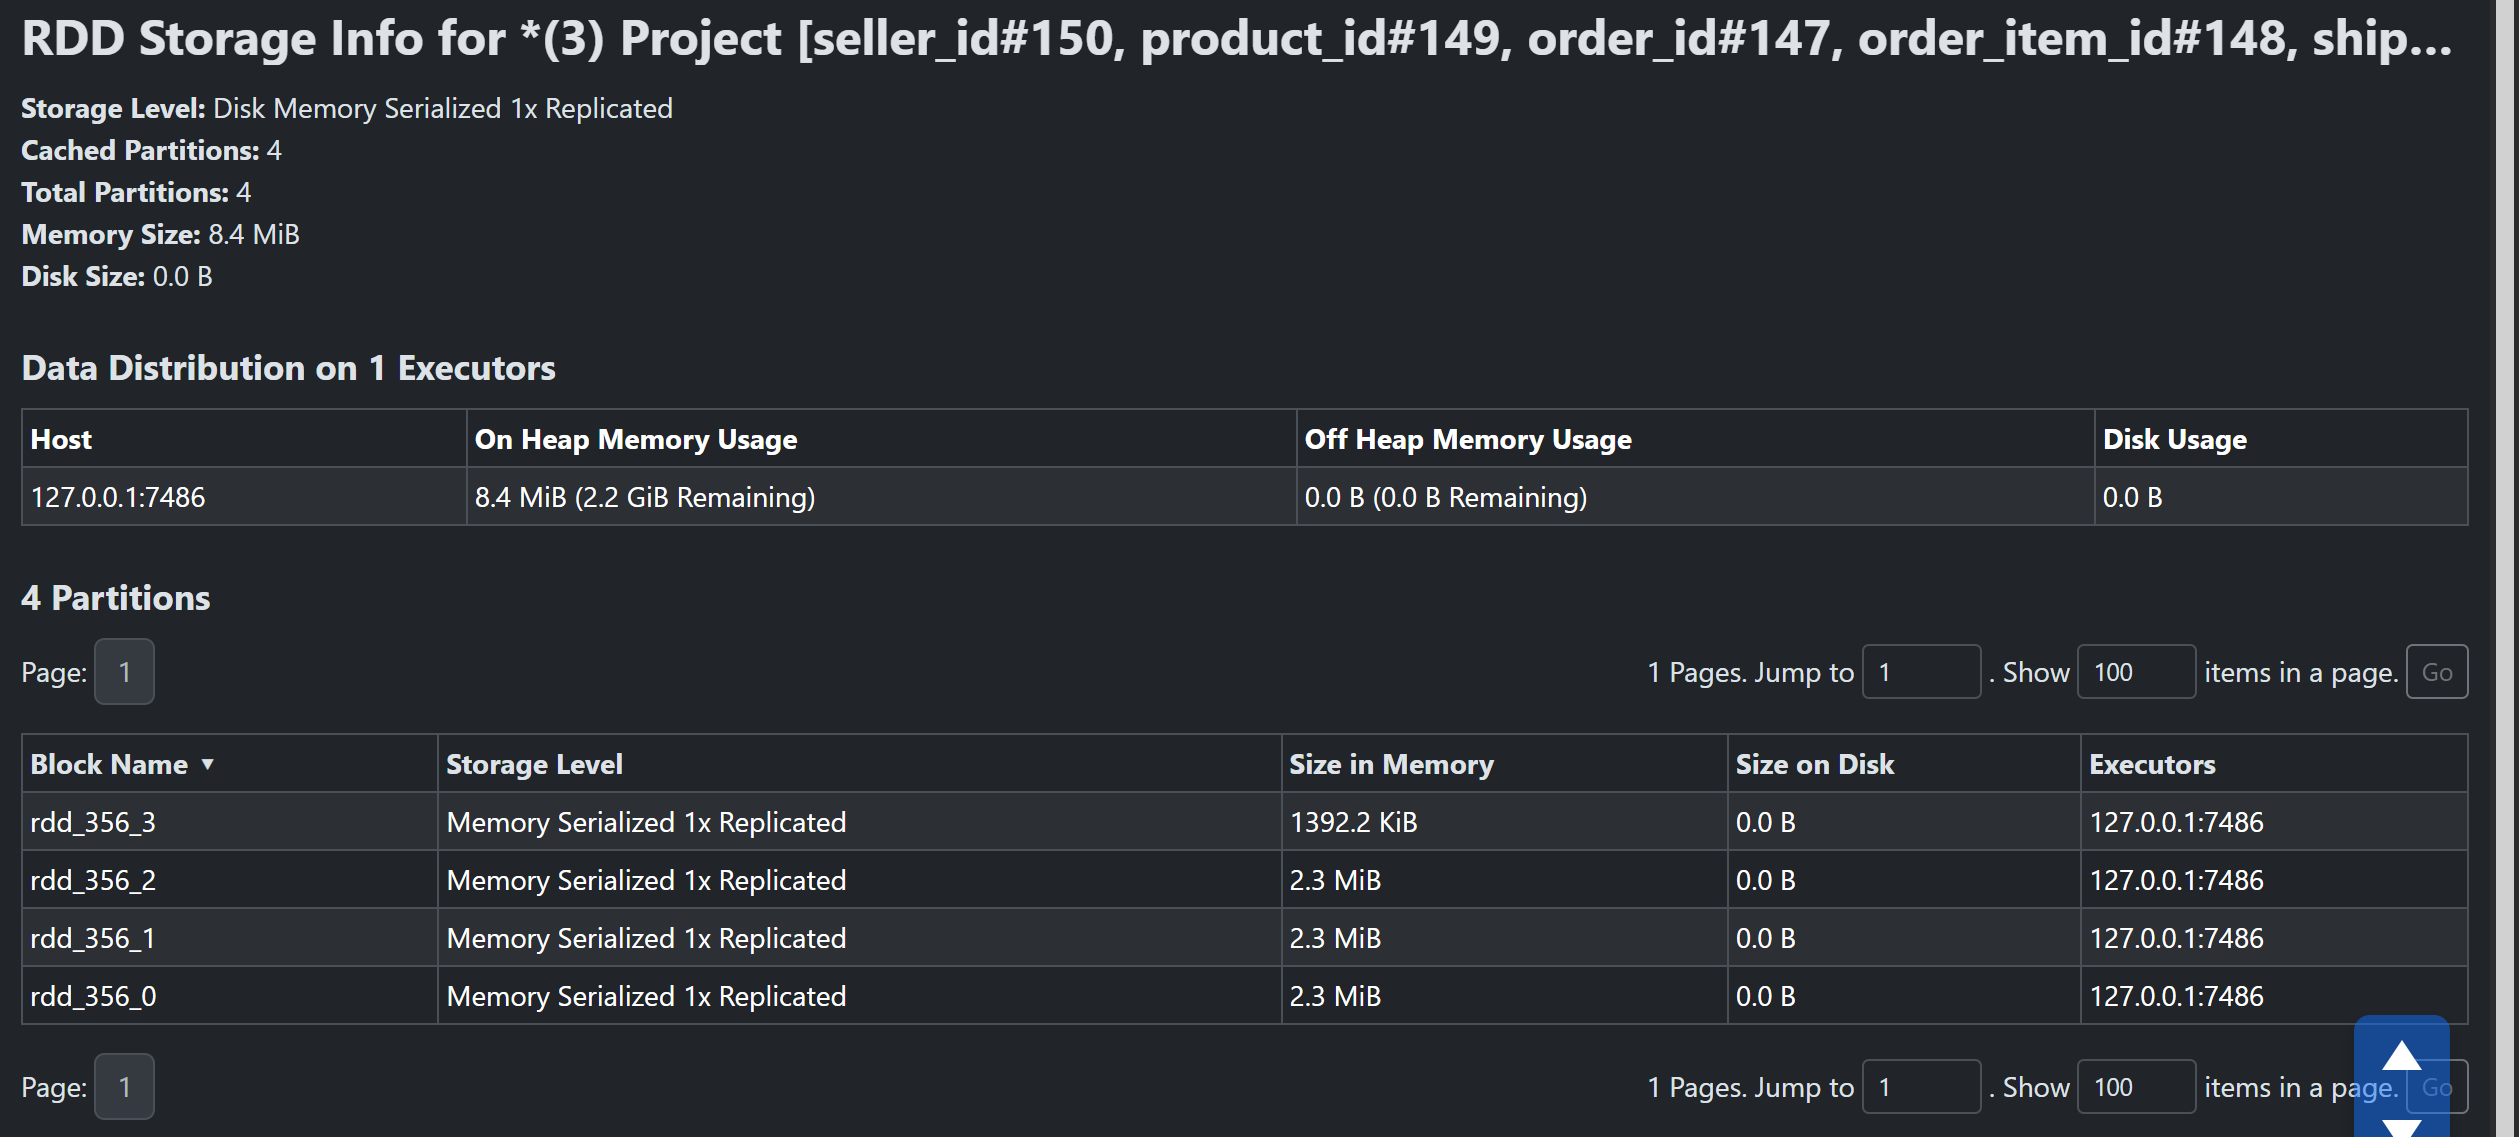

In [27]:
cached.unpersist(blocking=True)
print("После unpersist:", cached.is_cached, "  объектов в Storage:", len(ui_get("storage/rdd")))

table7 = pd.DataFrame([
    {"Вариант": "Без persist", "Подготовка/материализация, с": "-",
     "Action 1, с": round(nocache["a1"], 3), "Action 2, с": round(nocache["a2"], 3),
     "Итого, с": round(nocache["a1"] + nocache["a2"], 3)},
    {"Вариант": "MEMORY_AND_DISK", "Подготовка/материализация, с": round(withcache["mat"], 3),
     "Action 1, с": round(withcache["a1"], 3), "Action 2, с": round(withcache["a2"], 3),
     "Итого, с": round(sum(withcache.values()), 3)},
])
table7

После unpersist: False   объектов в Storage: 0


,Вариант,"Подготовка/материализация, с","Action 1, с","Action 2, с","Итого, с"
0,Без persist,—,0.366,0.286,0.652
1,MEMORY_AND_DISK,0.599,0.276,0.206,1.081


**Вывод:** без кэша два действия заняли 0.366 с и 0.286 с (всего 0.652 с). С `persist(MEMORY_AND_DISK)` материализация заняла 0.599 с,
а сами действия - 0.276 и 0.206 с: каждое стало быстрее, но с учётом материализации итог хуже (1.081 с). На двух действиях над небольшой витриной кэш не окупился.
Во вкладке Storage был виден объект уровня «Disk Memory Serialized 1x Replicated» (4 партиции, 8.4 Мб в памяти, на диск ничего не вытеснено);
стадии повторных действий читали эти 8,36 MiB из кэша, а после `unpersist()` вкладка Storage опустела. Контрольные суммы совпали (15 843 553,24).

## 12. Влияние числа партиций на время

### 12.1. Контролируемый бенчмарк на `spark.range`
Один прогрев и по три замера на каждое p; итог - медиана. `shuffle.partitions` фиксирован (8), меняется только число входных партиций.

In [28]:
N = 2_000_000
P_VALUES = [1, 2, 4, 8, 16, 32]
spark.conf.set("spark.sql.shuffle.partitions", "8")
sc.setJobGroup("P4_BENCH", "Бенчмарк spark.range", interruptOnCancel=True)

def run_benchmark(p, repeats=3):
    times, checksum = [], None
    for _ in range(repeats):
        df = (spark.range(0, N, 1, numPartitions=p)
              .withColumn("key", (F.col("id") % 1000).cast("int"))
              .withColumn("value", F.sqrt(F.col("id") + 1.0)))
        t0 = perf_counter()
        checksum = (df.groupBy("key").agg(F.sum("value").alias("s"))
                      .agg(F.sum("s").alias("checksum")).first()[0])
        times.append(perf_counter() - t0)
    return times, median(times), checksum

_ = run_benchmark(4, repeats=1)    # прогрев JVM
results = []
for p in P_VALUES:
    times, med, checksum = run_benchmark(p, repeats=3)
    results.append((p, *times, med))
    print(p, [round(t, 3) for t in times], round(med, 3), round(checksum, 2))

1 [0.159, 0.122, 0.105] 0.122 1885618790.06
2 [0.148, 0.134, 0.116] 0.134 1885618790.06
4 [0.131, 0.115, 0.106] 0.115 1885618790.06
8 [0.229, 0.177, 0.123] 0.177 1885618790.06
16 [0.248, 0.194, 0.18] 0.194 1885618790.06
32 [0.307, 0.28, 0.228] 0.28 1885618790.06


### 12.2. Относительное ускорение S(p) = T(1) / T(p)

In [29]:
table8 = pd.DataFrame(results, columns=["p", "Run 1, с", "Run 2, с", "Run 3, с", "Median, с"])
table8["S(p)=T(1)/T(p)"] = table8["Median, с"].iloc[0] / table8["Median, с"]
table8.round(3)

,p,"Run 1, с","Run 2, с","Run 3, с","Median, с",S(p)=T(1)/T(p)
0,1,0.159,0.122,0.105,0.122,1.000
1,2,0.148,0.134,0.116,0.134,0.911
2,4,0.131,0.115,0.106,0.115,1.057
3,8,0.229,0.177,0.123,0.177,0.688
4,16,0.248,0.194,0.180,0.194,0.630
5,32,0.307,0.280,0.228,0.280,0.435


### 12.3. Shuffle partitions отдельно от входных партиций
Вход зафиксирован на 8 партициях (и закэширован, чтобы не перечитывать файл), меняется только `spark.sql.shuffle.partitions`.
На 27 штатах большое q создаёт много пустых или почти пустых shuffle-партиций.

In [30]:
sc.setJobGroup("P4_SHUFFLE_Q", "Меняем spark.sql.shuffle.partitions", interruptOnCancel=True)
geo8 = geo.repartition(8).persist(StorageLevel.MEMORY_AND_DISK)
geo8.count()
Q_VALUES = [2, 4, 8, 16, 32]
q_rows = []
for q in Q_VALUES:
    spark.conf.set("spark.sql.shuffle.partitions", str(q))
    times = []
    for _ in range(3):
        t0 = perf_counter()
        groups = geo8.groupBy("geolocation_state").count().count()
        times.append(perf_counter() - t0)
    q_rows.append({"q": q, "groups": groups, "median, с": round(median(times), 3)})
    print(f"q={q:2d}; groups={groups}; times={[round(t, 3) for t in times]}")
spark.conf.set("spark.sql.shuffle.partitions", "8")   # возвращаем базовую настройку
geo8.unpersist(blocking=True)
pd.DataFrame(q_rows)

q= 2; groups=27; times=[0.198, 0.103, 0.069]
q= 4; groups=27; times=[0.129, 0.087, 0.097]
q= 8; groups=27; times=[0.124, 0.102, 0.149]
q=16; groups=27; times=[0.145, 0.142, 0.166]
q=32; groups=27; times=[0.218, 0.24, 0.227]


,q,groups,"median, с"
0,2,27,0.103
1,4,27,0.097
2,8,27,0.124
3,16,27,0.145
4,32,27,0.227


**Вывод:**
- **Входные партиции.** Лучшее время показал p = 4 (медиана 0.115 с);
  На этом стенде (20 логических CPU) задача на 2 млн строк слишком мала: на партицию уходят миллисекунды, и накладные расходы на планирование задач перевешивают выигрыш от параллелизма.
  Кроме того, каждая входная партиция даёт до 1000 частичных групп, поэтому объём shuffle растёт вместе с p. Ожидаемый компромисс «мало партиций - простаивают CPU» проявился бы на большем N.
- **Shuffle partitions.** При 27 штатах лучшее время у q = 4 (0.097 с), при q = 32 - 0.227 с: большая часть shuffle-партиций пустая, но под каждую всё равно создаётся задача.
  `spark.sql.shuffle.partitions` не меняет 8 входных партиций - он задаёт только число партиций после обмена.

## 13. Партиции и маленькие файлы

### 13.1. Запись `order_items` с разным числом партиций

In [31]:
OUT_SMALL = Path("small_files_experiment")
OUT_SMALL.mkdir(exist_ok=True)
sc.setJobGroup("P4_FILES", "Запись с разным числом партиций", interruptOnCancel=True)

def write_and_measure(df, p, prefix="p"):
    path = OUT_SMALL / f"{prefix}_{p}"
    t0 = perf_counter()
    df.repartition(p).write.mode("overwrite").parquet(str(path))
    elapsed = perf_counter() - t0
    files = list(path.glob("part-*.parquet"))
    sizes = [f.stat().st_size for f in files]
    return {"p": p, "part-файлов": len(files),
            "Общий размер, MiB": round(sum(sizes) / 1024**2, 3),
            "Средний файл, KiB": round(sum(sizes) / len(sizes) / 1024, 1) if sizes else 0,
            "Время записи, с": round(elapsed, 3)}

table9 = pd.DataFrame([write_and_measure(items, p) for p in [1, 4, 16, 64]])
table9

,p,part-файлов,"Общий размер, MiB","Средний файл, KiB","Время записи, с"
0,1,1,6.456,6611.2,1.233
1,4,4,7.432,1902.7,0.649
2,16,16,8.732,558.9,0.728
3,64,64,10.286,164.6,1.639


### 13.2. Почему `coalesce(1)` не универсален

In [32]:
single = items.coalesce(1)
print("Partitions before write:", single.rdd.getNumPartitions())
single.write.mode("overwrite").parquet(str(OUT_SMALL / "coalesce_1"))
print("Файлов:", len(list((OUT_SMALL / "coalesce_1").glob("part-*.parquet"))))

Partitions before write: 1
Файлов: 1


**Вывод:** число part-файлов совпало с p (1, 4, 16, 64), средний файл уменьшился с 6611 Кб при p = 1 до 165 Кб при p = 64.
Общий объём при этом не остался постоянным, а вырос с 6.46 до 10.29 Мб: у каждого Parquet-файла свои метаданные, а сжатие на маленьких файлах работает хуже.
Быстрее всего запись прошла при p = 4 (0.649 с), при p = 64 - 1.639 с. `coalesce(1)` дал один файл, но вся запись выполнялась одной задачей - для большого набора это потеря параллелизма.

### 13.3. Дополнительно: Adaptive Query Execution

In [33]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.shuffle.partitions", "32")
sc.setJobGroup("P4_AQE", "groupBy с AQE", interruptOnCancel=True)
adaptive = geo.groupBy("geolocation_state").count()
adaptive.collect()
adaptive.explain("formatted")  # после выполнения план показывает итоговое решение AQE
aqe_info = ui_summary("P4_AQE")
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.shuffle.partitions", "8")

== Physical Plan ==
AdaptiveSparkPlan (12)
+- == Final Plan ==
   ResultQueryStage (8)
   +- * HashAggregate (7)
      +- AQEShuffleRead (6), coalesced
         +- ShuffleQueryStage (5), Statistics(sizeInBytes=1568.0 B, rowCount=49)
            +- Exchange (4)
               +- * HashAggregate (3)
                  +- * ColumnarToRow (2)
                     +- Scan parquet  (1)
+- == Initial Plan ==
   HashAggregate (11)
   +- Exchange (10)
      +- HashAggregate (9)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [1]: [geolocation_state#146]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/geolocation]
ReadSchema: struct<geolocation_state:string>

(2) ColumnarToRow [codegen id : 1]
Input [1]: [geolocation_state#146]

(3) HashAggregate [codegen id : 1]
Input [1]: [geolocation_state#146]
Keys [1]: [geolocation_state#146]
Functions [1]: [partial_count(1)]
Aggregate Attributes [1]: [count#4368L]
Results [2]: [geolocation_state#146, count

,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,225,COMPLETE,16,0.1,3.2,0.0,collect at C:\Users\Владимир Савинский\AppData...
1,226,SKIPPED,16,0.0,0.0,0.0,collect at C:\Users\Владимир Савинский\AppData...
2,227,COMPLETE,1,0.0,0.0,3.2,collect at C:\Users\Владимир Савинский\AppData...


AQE: true


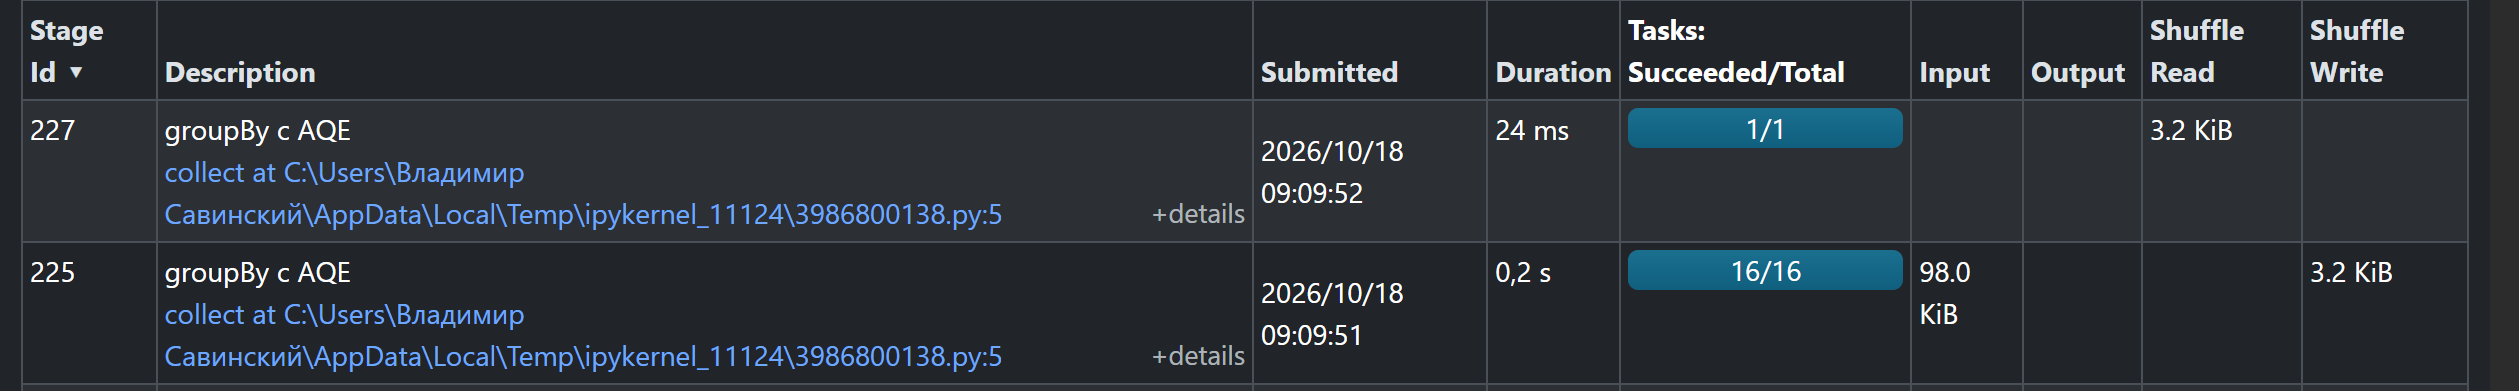

**Вывод:** с AQE в плане появился `AdaptiveSparkPlan (isFinalPlan=true)`: исходный план содержал `Exchange hashpartitioning(geolocation_state, 32)`,
а финальный - `AQEShuffleRead coalesced`. По фактической статистике (49 строк, 1,5 KiB) AQE объединил 32 мелкие shuffle-партиции, и в UI финальная стадия выполнилась одной Task вместо 32.
Для основных опытов AQE был выключен, иначе Spark сам менял бы число партиций и стратегии, и эффект отдельного параметра было бы не выделить

### Журнал наблюдений Spark UI по учебной части

In [34]:
table10 = pd.DataFrame(JOURNAL)
table10

,Эксперимент,Jobs,Stages (выполнено / пропущено),Tasks по стадиям,"Shuffle Write, KiB","Shuffle Read, KiB",Что подтверждает UI
0,repartition(4),1,4 / 0,16 - 16 - 4 - 8,173.8,173.8,полный shuffle: Exchange перед финальной стадией
1,coalesce(4),1,3 / 0,16 - 4 - 8,153.1,153.1,объединение партиций без полного shuffle
2,groupBy seller_id,1,2 / 0,4 - 8,438.6,438.6,граница стадий на Exchange hashpartitioning(se...
3,Sort Merge Join,1,4 / 0,1 - 4 - 8 - 1,3832.9,3832.9,Exchange + Sort с обеих сторон перед SortMerge...
4,Broadcast Hash Join,2,3 / 0,1 - 4 - 1,0.2,0.2,"отдельный Job для broadcast, большая сторона б..."
5,Sort Merge Join,1,4 / 0,1 - 4 - 8 - 1,3832.9,3832.9,Exchange + Sort с обеих сторон перед SortMerge...
6,Broadcast Hash Join,2,3 / 0,1 - 4 - 1,0.2,0.2,"отдельный Job для broadcast, большая сторона б..."
7,persist + повторный Action,5,10 / 0,1 - 1 - 4 - 1 - 4 - 8 - 1 - 4 - 8 - 1,15.9,15.9,повторные действия читают кэш (InMemoryTableSc...


**Выводы по учебной части:**
1. **Lazy evaluation.** Цепочка из трёх transformations над geolocation строилась 76,5 мс и не создала ни одного Job; `count()` запустил 1 Job из 2 Stages (16 Tasks чтения и 1 итоговая) и занял 0,575 с.
2. **Партиции и Tasks.** geolocation читается в 16 партициях, order_items - в 4; число Tasks первой стадии всегда совпадало с числом входных партиций, а стадии после shuffle имели 8 Tasks - по `spark.sql.shuffle.partitions`.
3. **Перекос ключа.** На SP приходится 40,42% строк geolocation; хэширование по штату заполнило лишь 12 из 16 партиций с разницей размеров в 358 раз (1 301 и 466 119 строк).
4. **repartition и coalesce.** repartition(4) выполнил полный shuffle (Exchange RoundRobinPartitioning) и выровнял партиции до 250 040–250 041 строк (max/mean = 1,00); coalesce(4) обошёлся без нового Exchange, но сохранил перекос - от 88 462 до 626 485 строк (max/mean = 2,51).
5. **Shuffle при groupBy.** Агрегация по seller_id двухфазная: до обмена каждая из 4 партиций сворачивается до частичных итогов по продавцам, между фазами передано 438,6 KiB, финальная агрегация выполнена в 8 Tasks.
6. **Стратегии JOIN.** Sort Merge Join перемешал обе стороны (3,8 MiB shuffle, 4 Stages) и выполнился за 0,533 с; Broadcast Hash Join обошёлся без shuffle большой стороны (отдельный Job рассылки products, 3 Stages) за 0,359 с при одинаковом результате - 112 650 строк.
7. **cache/persist.** Каждое действие над кэшем стало быстрее (0,276 и 0,206 с против 0,366 и 0,286 с), но с учётом материализации (0,599 с) итог хуже - 1,081 с против 0,652 с: на двух действиях кэш не окупился.
8. **Число партиций.** На 2 млн строк лучшее время дал p = 4 (0,115 с, S = 1,06), почти столько же - p = 1 (0,122 с); при p = 32 расчёт занял 0,280 с, в 2,4 раза дольше оптимума, - накладные расходы на короткие задачи перевешивают параллелизм. Для 27 групп оптимум shuffle partitions - q = 4 (0,097 с), при q = 32 - 0,227 с.
9. **Маленькие файлы.** Число part-файлов совпало с p; 64 партиции дали 64 файла по 165 KiB и на 59% больший общий объём, чем один файл (10,29 против 6,46 MiB). Быстрее всего запись прошла при p = 4 (0,649 с), а при p = 1 (1,233 с) и p = 64 (1,639 с) - медленнее: одна задача не использует параллелизм, а 64 задачи тратят время на создание множества мелких файлов.
10. **AQE.** При включённом AQE исходный Exchange на 32 партиции по фактической статистике (49 строк, 1,5 KiB) был объединён: финальная стадия выполнилась одной Task вместо 32.

## 14. Самостоятельная часть. Вариант D: `order_items` + `products`

| Основная таблица | Справочник | Ключ | Группировка |
|---|---|---|---|
| `order_items` (позиции заказов) | `products` (товары) | `product_id` | `product_category_name` |

Вычислительный граф отличается от учебного: соединение строит витрину «позиция заказа + категория и вес товара»,
а группировка идёт по категории - ключу с заметным перекосом (несколько категорий дают большую часть продаж).

### 14.1. Данные: строки и исходные партиции

In [35]:
sc.setJobGroup("D_DATA", "Вариант D: чтение таблиц", interruptOnCancel=True)
items_d = spark.read.parquet(str(PARQUET / "order_items"))
products_d = spark.read.parquet(str(PARQUET / "products"))

data_d = pd.DataFrame([
    {"Таблица": "order_items", "Строк": items_d.count(), "Столбцов": len(items_d.columns),
     "Партиций": items_d.rdd.getNumPartitions(), "Уникальных product_id": items_d.select("product_id").distinct().count()},
    {"Таблица": "products", "Строк": products_d.count(), "Столбцов": len(products_d.columns),
     "Партиций": products_d.rdd.getNumPartitions(), "Уникальных product_id": products_d.select("product_id").distinct().count()},
])
items_d.printSchema()
products_d.printSchema()
data_d

root
 |-- order_id: string (nullable = true)
 |-- order_item_id: integer (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_value: double (nullable = true)

root
 |-- product_id: string (nullable = true)
 |-- product_category_name: string (nullable = true)
 |-- product_name_lenght: double (nullable = true)
 |-- product_description_lenght: double (nullable = true)
 |-- product_photos_qty: double (nullable = true)
 |-- product_weight_g: double (nullable = true)
 |-- product_length_cm: double (nullable = true)
 |-- product_height_cm: double (nullable = true)
 |-- product_width_cm: double (nullable = true)



,Таблица,Строк,Столбцов,Партиций,Уникальных product_id
0,order_items,112650,7,4,32951
1,products,32951,9,1,32951


**Вывод:** order_items - 112 650 строк в 4 партициях, products - 32 951 строка в 1 партиции. `product_id` в products уникален,
и в order_items встречаются все 32 951 товар, поэтому INNER JOIN сохранит все 112 650 позиций и не размножит строки

### 14.2. Lazy evaluation
Цепочка из четырёх transformations: отбор столбцов, фильтр по цене, расчёт полной стоимости и доли доставки. Число Jobs проверяется до и после Action.

In [36]:
sc.setJobGroup("D_LAZY", "Вариант D: lazy evaluation", interruptOnCancel=True)
t0 = perf_counter()
items_prepared = (
    items_d
    .select("order_id", "product_id", "seller_id", "price", "freight_value")
    .filter(F.col("price") > 0)
    .withColumn("gross_value", F.col("price") + F.col("freight_value"))
    .withColumn("freight_share", F.round(F.col("freight_value") / F.col("gross_value"), 4))
)
t_build = perf_counter() - t0
print(f"Построение цепочки: {t_build * 1000:.1f} мс; Jobs до Action: {jobs_in_group('D_LAZY')}")

t0 = perf_counter()
n_prepared = items_prepared.count()
t_action = perf_counter() - t0
print(f"Action count(): {n_prepared} строк за {t_action:.3f} с; Jobs после Action: {jobs_in_group('D_LAZY')}")
d_lazy = ui_summary("D_LAZY")

Построение цепочки: 30.0 мс; Jobs до Action: 0
Action count(): 112650 строк за 0.093 с; Jobs после Action: 1
Группа D_LAZY: Jobs = 1, Stages = 2


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,240,COMPLETE,4,0.29,0.2,0.0,count at DirectMethodHandleAccessor.java:103
1,241,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103


**Вывод:** цепочка из четырёх преобразований (`select - filter - withColumn x2`) строилась 102.8 мс без единого Job.
`count()` запустил 1 Job из 2 Stages (4 Tasks по числу партиций order_items и 1 итоговая) и занял 0.318 с.
Фильтр `price > 0` не отбросил ни одной строки (112 650), а в плане он передан прямо в источник (`PushedFilters`)
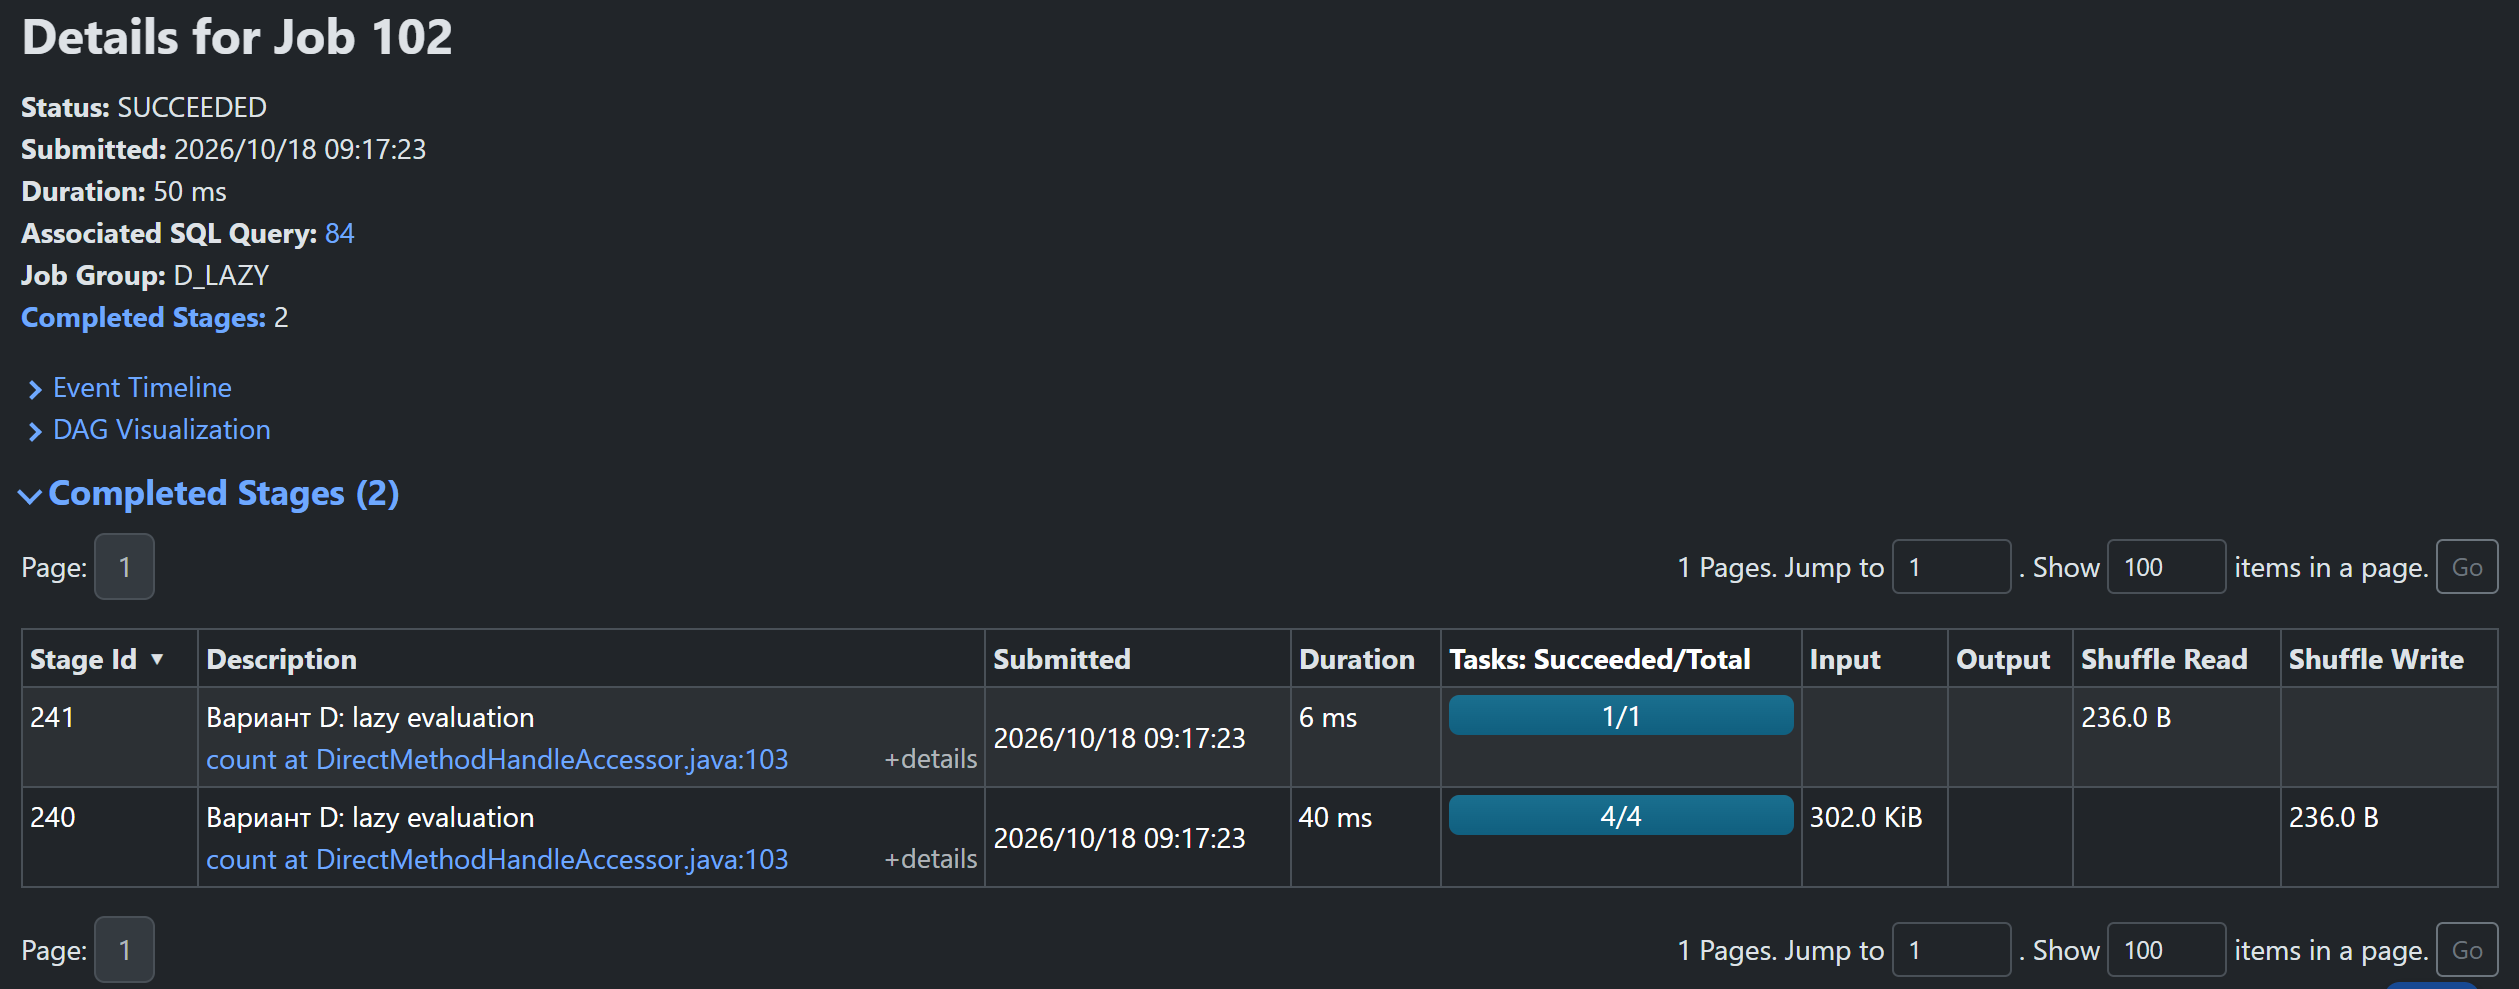

### 14.3. `repartition()` / `coalesce()` на ключе с перекосом
Позиции заказов получают категорию товара (broadcast маленького справочника), раскладываются на 16 партиций по категории,
затем уменьшаются до 4 двумя способами

In [37]:
cat_small = products_d.select("product_id", "product_category_name")
items_cat = items_prepared.join(F.broadcast(cat_small), "product_id", "left")

skewed_d = items_cat.repartition(16, "product_category_name")
repart_d = skewed_d.repartition(4)
coal_d = skewed_d.coalesce(4)

print("=== repartition(4) ===")
repart_d.explain("formatted")
print("=== coalesce(4) ===")
coal_d.explain("formatted")

=== repartition(4) ===
== Physical Plan ==
Exchange (12)
+- * Project (11)
   +- * BroadcastHashJoin LeftOuter BuildRight (10)
      :- * Project (5)
      :  +- * Project (4)
      :     +- * Filter (3)
      :        +- * ColumnarToRow (2)
      :           +- Scan parquet  (1)
      +- BroadcastExchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [5]: [order_id#4370, product_id#4372, seller_id#4373, price#4375, freight_value#4376]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(price), GreaterThan(price,0.0)]
ReadSchema: struct<order_id:string,product_id:string,seller_id:string,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 2]
Input [5]: [order_id#4370, product_id#4372, seller_id#4373, price#4375, freight_value#4376]

(3) Filter [codegen id : 2]
Input [5]: [order_id#4370, product_id#4372, seller_id#4

In [38]:
sc.setJobGroup("D_REPART", "Вариант D: профили партиций", interruptOnCancel=True)
table_d_part = pd.DataFrame([profile_stats(skewed_d, "skewed16 по категории"),
                             profile_stats(repart_d, "repartition(4)"),
                             profile_stats(coal_d, "coalesce(4)")])
table_d_part

,Вариант,непустых партиций,min rows,max rows,mean rows,max / mean
0,skewed16 по категории,15,209,18371,7510.0,2.45
1,repartition(4),4,28161,28164,28162.5,1.00
2,coalesce(4),4,19375,35256,28162.5,1.25


**Вывод:**
- **Исходная раскладка.** Хэширование по категории заполнило 15 из 16 партиций, размеры - от 209 до 18 371 строк (max/mean = 2,45).
  Перекос заметный, но мягче, чем по штатам в учебной части (5,59): 73 категории распределяются ровнее, чем 27 штатов с доминирующим SP.
- **repartition(4).** Снова полный shuffle (`Exchange RoundRobinPartitioning(4)`), партиции выровнены до 28 161–28 164 строк.
- **coalesce(4).** Хэш-партиции склеены без нового обмена (`Coalesce 4` над `Exchange hashpartitioning`), разброс сохранился: от 19 375 до 35 256 строк (max/mean = 1,25).

Вывод тот же, что в учебной части: coalesce дешевле, но равномерности не гарантирует.

### 14.4. `groupBy()` по категории и shuffle

In [39]:
sc.setJobGroup("D_GROUPBY", "Вариант D: groupBy product_category_name", interruptOnCancel=True)
category_stats = (
    items_cat
    .groupBy("product_category_name")
    .agg(F.count("*").alias("items"),
         F.countDistinct("order_id").alias("orders"),
         F.round(F.sum("price"), 2).alias("revenue"),
         F.round(F.avg("price"), 2).alias("avg_price"),
         F.round(F.avg("freight_share"), 4).alias("avg_freight_share"))
    .orderBy(F.desc("revenue"))
)
category_stats.show(10, truncate=False)
category_stats.explain("formatted")
d_groupby = ui_summary("D_GROUPBY")

+----------------------+-----+------+----------+---------+-----------------+
|product_category_name |items|orders|revenue   |avg_price|avg_freight_share|
+----------------------+-----+------+----------+---------+-----------------+
|beleza_saude          |9670 |8836  |1258681.34|130.16   |0.1991           |
|relogios_presentes    |5991 |5624  |1205005.68|201.14   |0.1313           |
|cama_mesa_banho       |11115|9417  |1036988.68|93.3     |0.2031           |
|esporte_lazer         |8641 |7720  |988048.97 |114.34   |0.2036           |
|informatica_acessorios|7827 |6689  |911954.32 |116.51   |0.2028           |
|moveis_decoracao      |8334 |6449  |729762.49 |87.56    |0.2327           |
|cool_stuff            |3796 |3632  |635290.85 |167.36   |0.1631           |
|utilidades_domesticas |6964 |5884  |632248.66 |90.79    |0.2516           |
|automotivo            |4235 |3897  |592720.11 |139.96   |0.2148           |
|ferramentas_jardim    |4347 |3518  |485256.46 |111.63   |0.2302           |

,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,268,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
1,269,COMPLETE,4,0.29,6049.5,0.0,showString at DirectMethodHandleAccessor.java:103
2,270,COMPLETE,8,0.00,37.6,6049.5,showString at DirectMethodHandleAccessor.java:103
3,271,COMPLETE,8,0.00,0.0,37.6,showString at DirectMethodHandleAccessor.java:103


**Вывод:**
- **Результат.** Больше всего выручки у категории beleza_saude (1258681,34; 9670 позиций), больше всего позиций - у cama_mesa_banho (11115),
  самая высокая средняя цена - у relogios_presentes (201,14).
- **План.** Он сложнее учебного: из-за `countDistinct(order_id)` агрегация идёт в два уровня - сначала по паре «категория + заказ», затем по категории.
  Поэтому в плане два Exchange и четыре HashAggregate, плюс ещё один Exchange для сортировки.
- **Spark UI.** 2 Jobs: рассылка справочника (1 Task) и сама агрегация. 4 Tasks записали 6049.5 Кб shuffle, следующая стадия из 8 Tasks прочитала их и передала дальше всего 37.6 Кб.
  Основной объём обмена создаёт именно `countDistinct`: по ключу с order_id почти каждая строка уникальна, и частичная агрегация её не сокращает.
  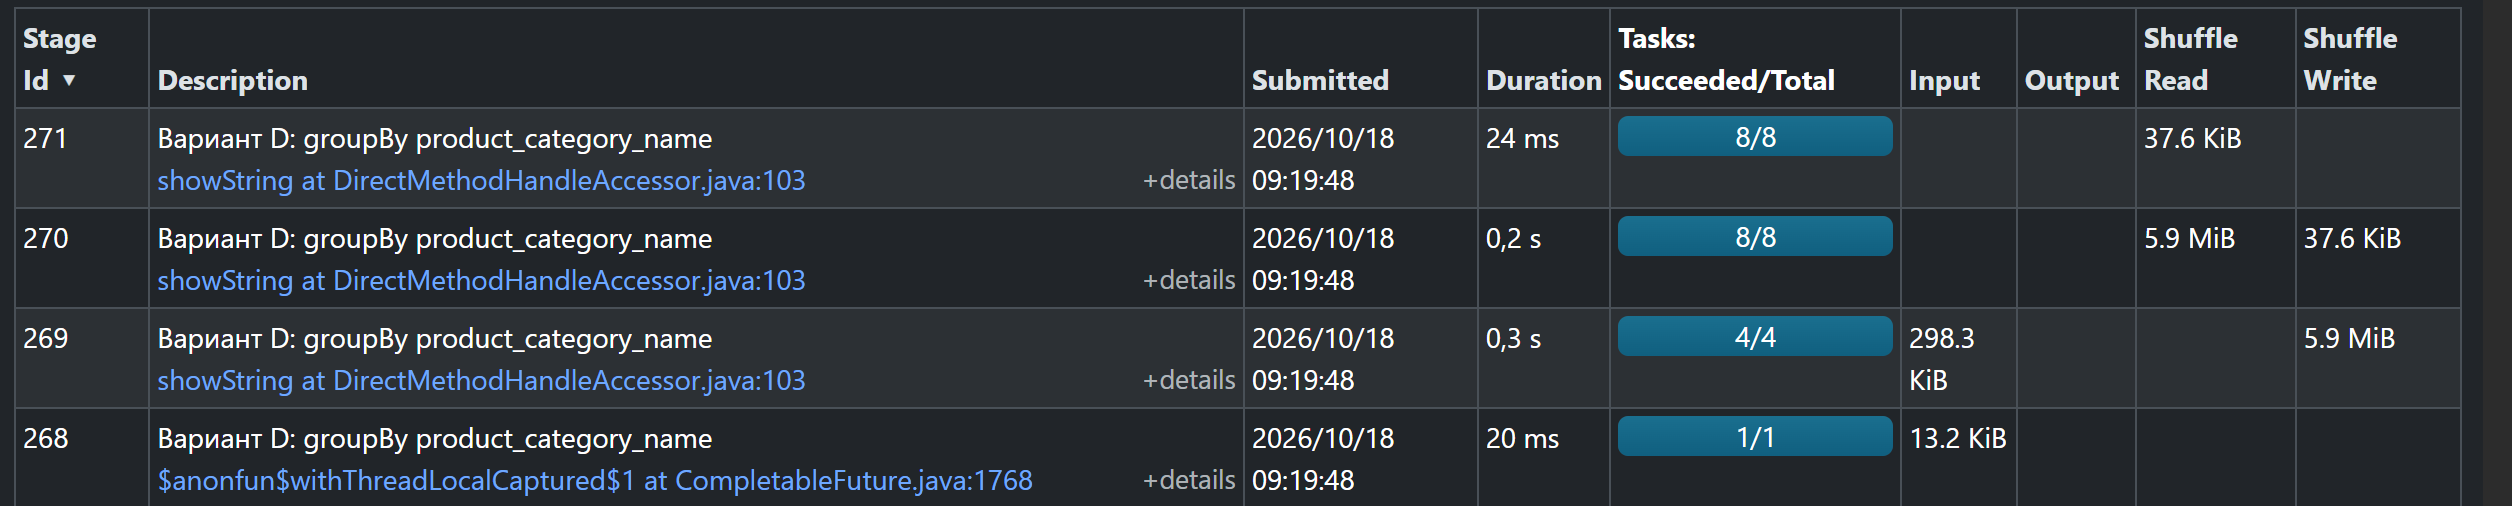

### 14.5. Один JOIN двумя стратегиями
Запрос одинаковый: позиции заказов x товары (категория и вес) по `product_id`.
Каждая стратегия запускается 3 раза, итог - медиана.

In [40]:
products_join = products_d.select("product_id", "product_category_name", "product_weight_g")
left_side = items_d.select("order_id", "product_id", "price", "freight_value")

def timed_count(df, repeats=3):
    times, rows = [], None
    for _ in range(repeats):
        t0 = perf_counter(); rows = df.count(); times.append(perf_counter() - t0)
    return rows, times, median(times)

sc.setJobGroup("D_SMJ", "Вариант D: Sort Merge Join", interruptOnCancel=True)
d_smj = left_side.hint("merge").join(products_join.hint("merge"), "product_id", "inner")
d_smj.explain("formatted")
d_smj_rows, d_smj_times, d_smj_med = timed_count(d_smj)
d_smj_info = ui_summary("D_SMJ", show=False)

sc.setJobGroup("D_BHJ", "Вариант D: Broadcast Hash Join", interruptOnCancel=True)
d_bhj = left_side.join(F.broadcast(products_join), "product_id", "inner")
d_bhj.explain("formatted")
d_bhj_rows, d_bhj_times, d_bhj_med = timed_count(d_bhj)
d_bhj_info = ui_summary("D_BHJ", show=False)

assert d_smj_rows == d_bhj_rows, "Стратегии дали разное число строк"
table_d_join = pd.DataFrame({
    "Показатель": ["Строк результата", "Jobs / Stages", "Shuffle Write / Read, KiB",
                   "Замеры, с", "Медиана, с"],
    "Sort Merge Join": [d_smj_rows, f"{d_smj_info['jobs']} / {len(d_smj_info['stages'])}",
                        f"{shuffle_sum(d_smj_info, 'shuffle_write_KiB')} / {shuffle_sum(d_smj_info, 'shuffle_read_KiB')}",
                        ", ".join(f"{t:.3f}" for t in d_smj_times), round(d_smj_med, 3)],
    "Broadcast Hash Join": [d_bhj_rows, f"{d_bhj_info['jobs']} / {len(d_bhj_info['stages'])}",
                            f"{shuffle_sum(d_bhj_info, 'shuffle_write_KiB')} / {shuffle_sum(d_bhj_info, 'shuffle_read_KiB')}",
                            ", ".join(f"{t:.3f}" for t in d_bhj_times), round(d_bhj_med, 3)],
})
display(d_smj_info["stages"]); display(d_bhj_info["stages"])
table_d_join

== Physical Plan ==
* Project (12)
+- * SortMergeJoin Inner (11)
   :- * Sort (5)
   :  +- Exchange (4)
   :     +- * Filter (3)
   :        +- * ColumnarToRow (2)
   :           +- Scan parquet  (1)
   +- * Sort (10)
      +- Exchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [4]: [order_id#4370, product_id#4372, price#4375, freight_value#4376]
Batched: true
Location: InMemoryFileIndex [file:/D:/BigData_Practicies/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,product_id:string,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [4]: [order_id#4370, product_id#4372, price#4375, freight_value#4376]

(3) Filter [codegen id : 1]
Input [4]: [order_id#4370, product_id#4372, price#4375, freight_value#4376]
Condition : isnotnull(product_id#4372)

(4) Exchange
Input [4]: [order_id#4370, product_id#4372, price#4375, freight_va

,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,272,COMPLETE,1,0.01,1088.3,0.0,count at DirectMethodHandleAccessor.java:103
1,273,COMPLETE,4,0.04,2744.1,0.0,count at DirectMethodHandleAccessor.java:103
2,274,COMPLETE,8,0.00,0.5,3832.4,count at DirectMethodHandleAccessor.java:103
3,275,COMPLETE,1,0.00,0.0,0.5,count at DirectMethodHandleAccessor.java:103
4,276,COMPLETE,4,0.04,2744.1,0.0,count at DirectMethodHandleAccessor.java:103
5,277,COMPLETE,1,0.01,1088.3,0.0,count at DirectMethodHandleAccessor.java:103
6,278,COMPLETE,8,0.00,0.5,3832.4,count at DirectMethodHandleAccessor.java:103
7,279,COMPLETE,1,0.00,0.0,0.5,count at DirectMethodHandleAccessor.java:103
8,280,COMPLETE,4,0.04,2744.1,0.0,count at DirectMethodHandleAccessor.java:103
9,281,COMPLETE,1,0.01,1088.3,0.0,count at DirectMethodHandleAccessor.java:103


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,284,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
1,285,COMPLETE,4,0.04,0.2,0.0,count at DirectMethodHandleAccessor.java:103
2,286,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103
3,287,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
4,288,COMPLETE,4,0.04,0.2,0.0,count at DirectMethodHandleAccessor.java:103
5,289,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103
6,290,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
7,291,COMPLETE,4,0.04,0.2,0.0,count at DirectMethodHandleAccessor.java:103
8,292,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103


,Показатель,Sort Merge Join,Broadcast Hash Join
0,Строк результата,112650,112650
1,Jobs / Stages,3 / 12,6 / 9
2,"Shuffle Write / Read, KiB",11498.7 / 11498.7,0.6 / 0.6
3,"Замеры, с","0.386, 0.184, 0.191","0.138, 0.149, 0.139"
4,"Медиана, с",0.191,0.139


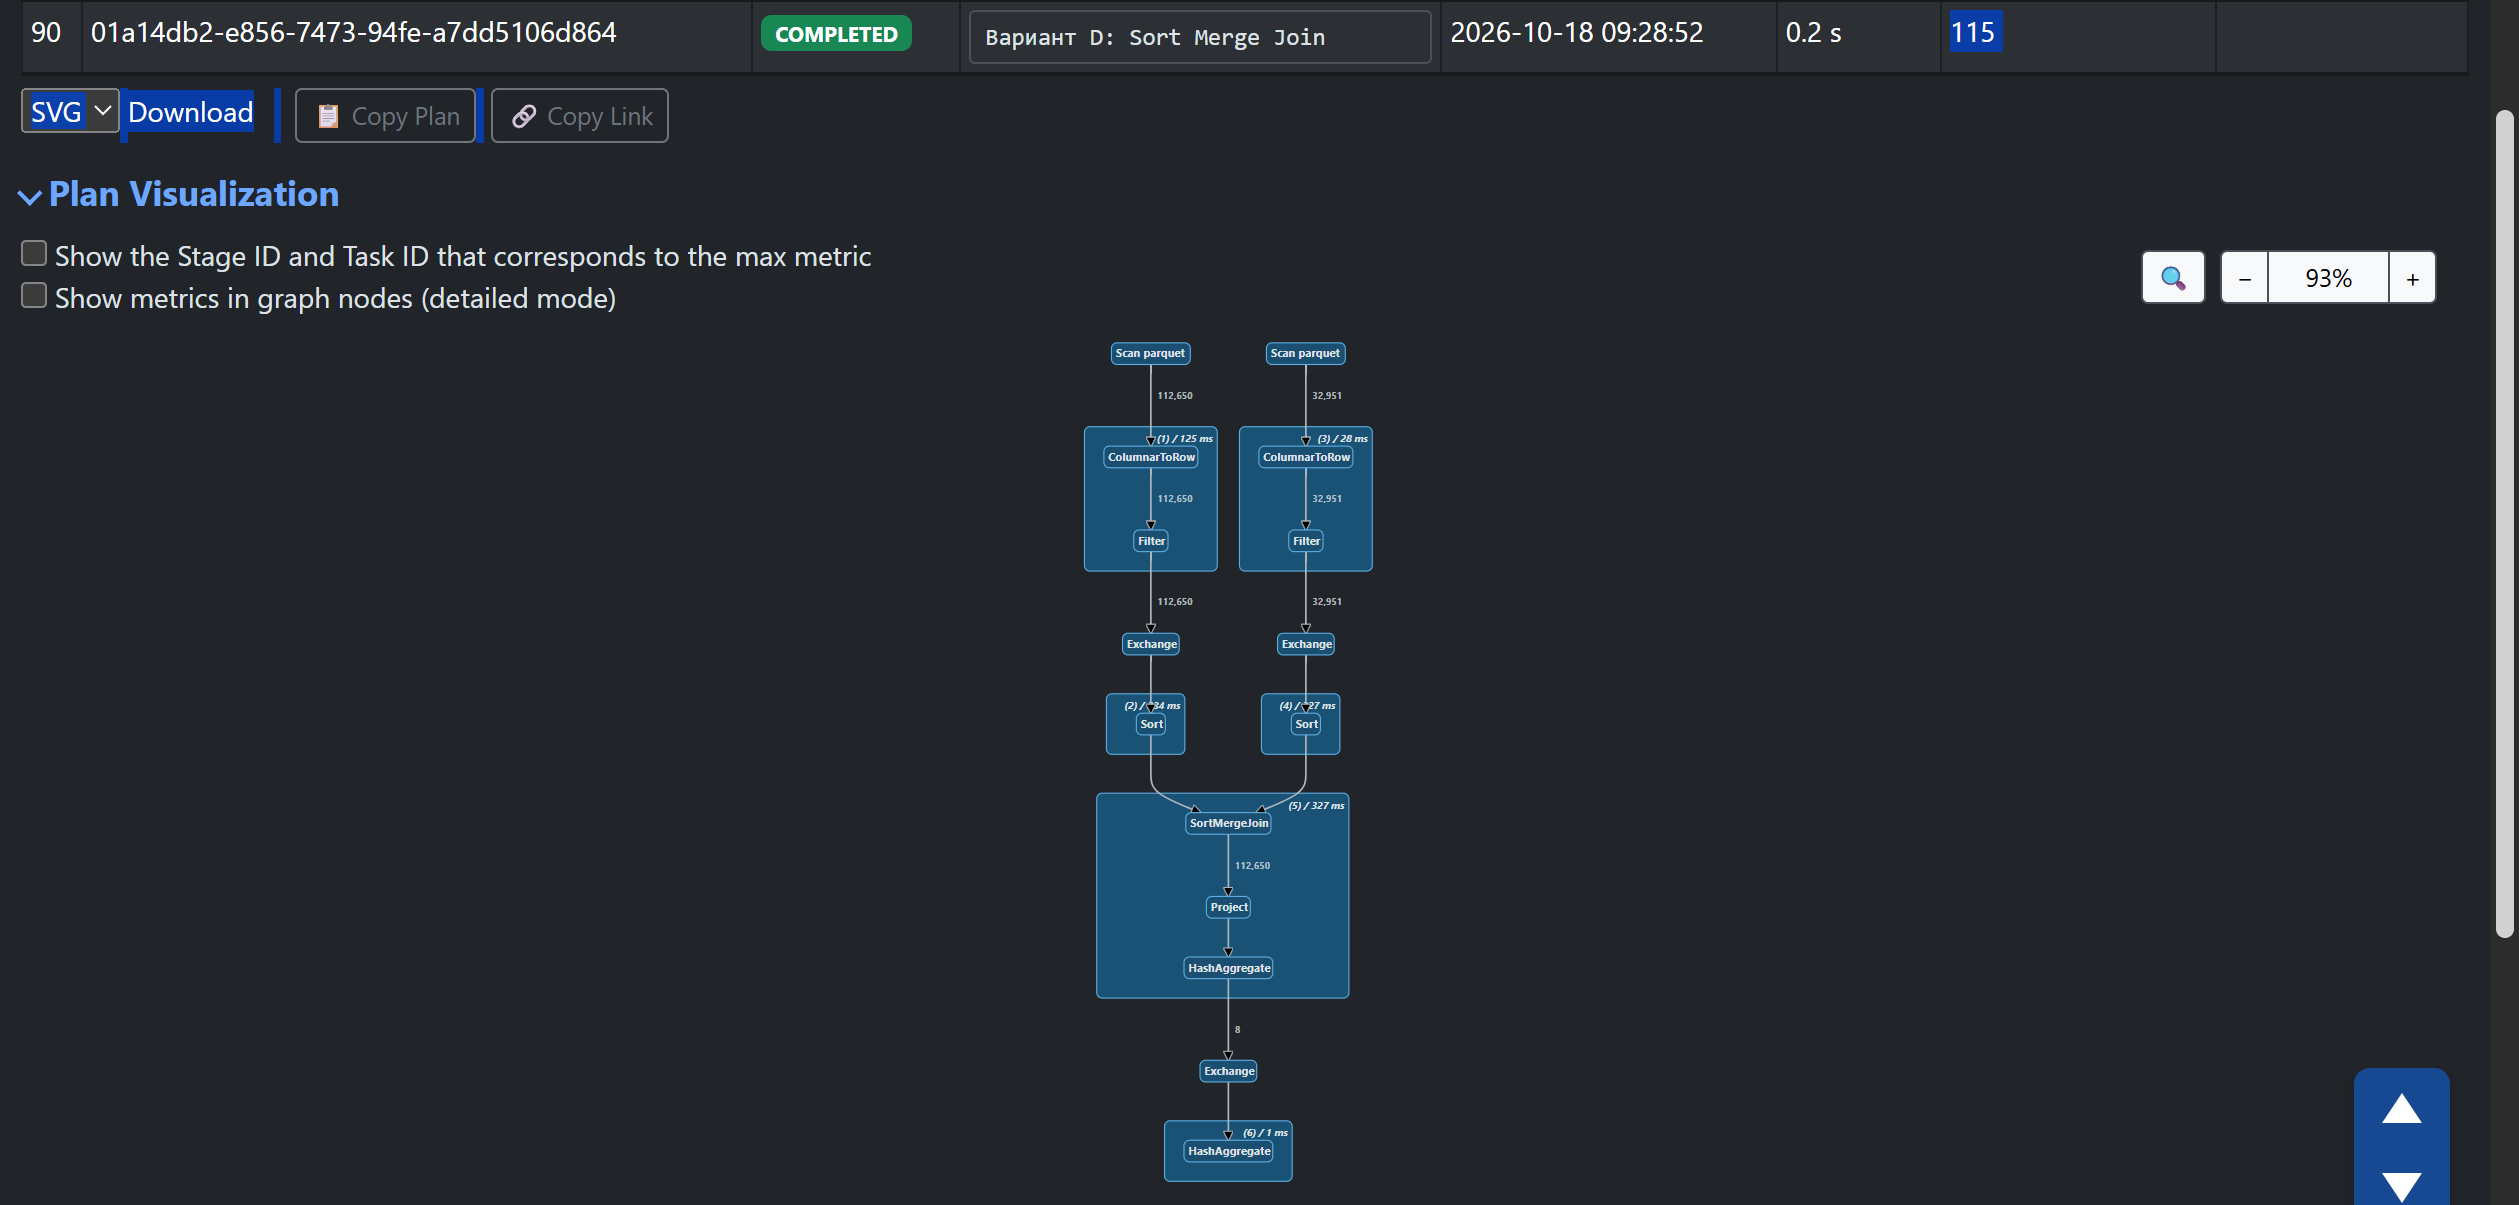

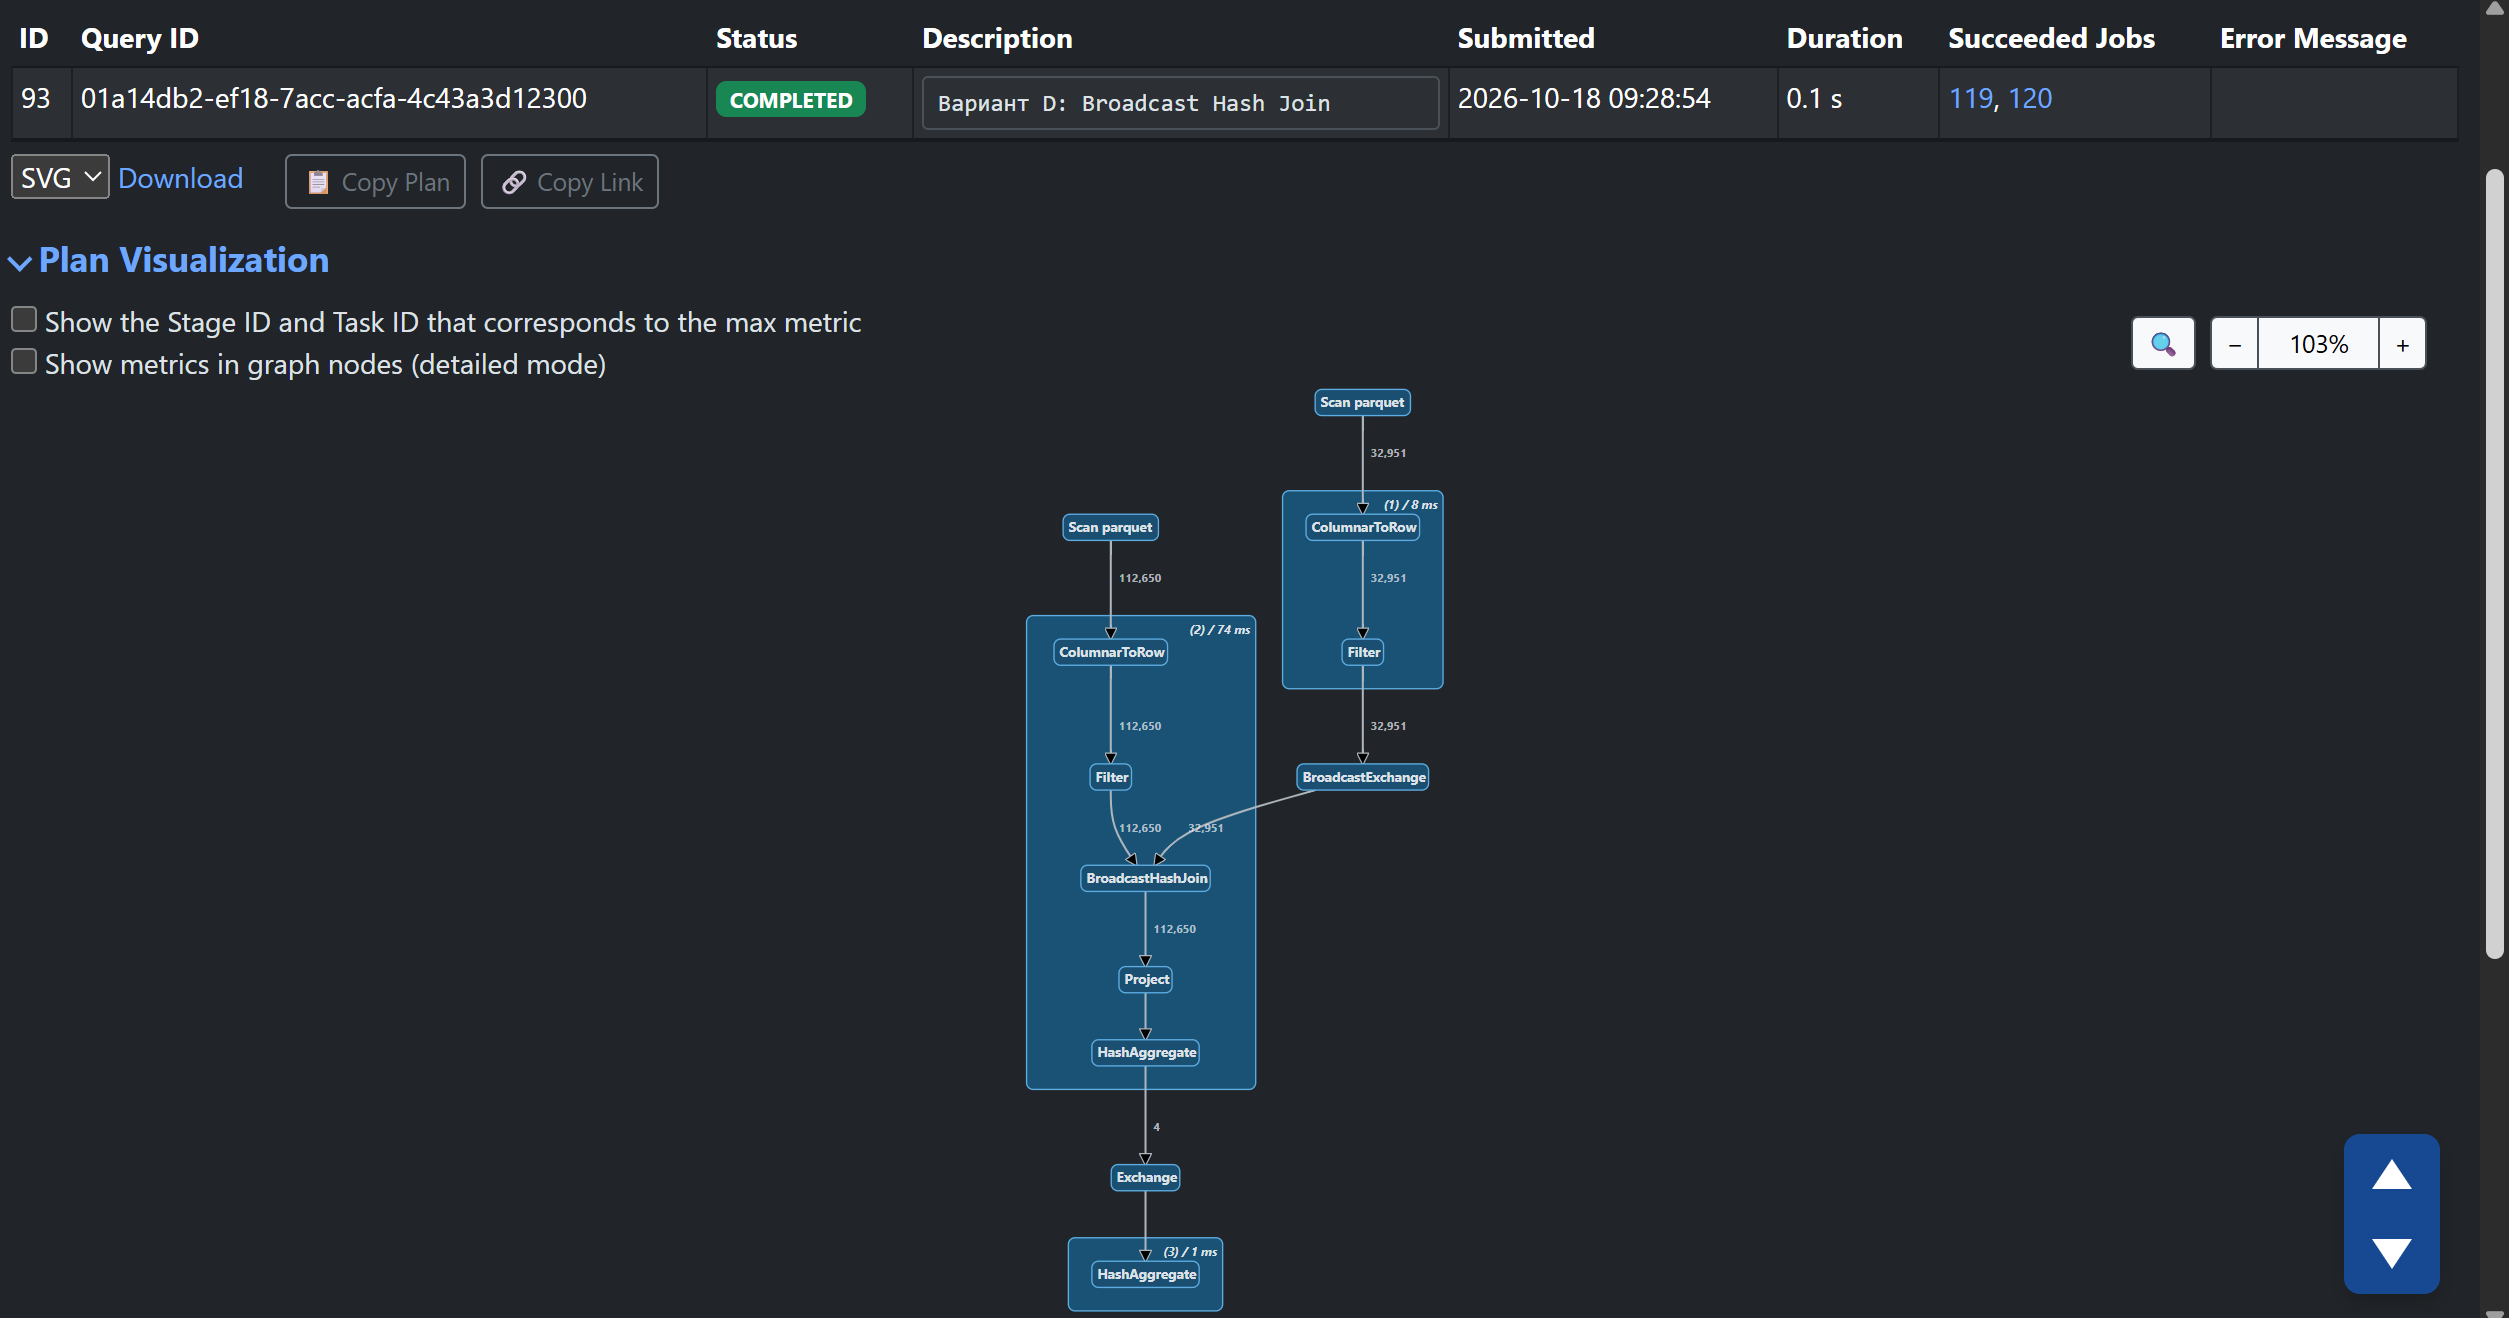

**Вывод:**
- **Результат.** Обе стратегии вернули 112650 строк: запросы логически эквивалентны.
- **Shuffle.** Sort Merge Join в каждом запуске перемешивал обе стороны (3833 Кб за запуск, 11499 Кб за три).
  Broadcast Hash Join обходился без shuffle большой стороны (0.6 Кб за три запуска - только итоговый count), но каждый раз запускал отдельный Job для рассылки справочника - отсюда 6 Jobs на 3 запуска против 3 у SMJ.
- **Время.** Broadcast Hash Join оказался быстрее, как и в учебной части: медиана 0,139 с против 0,191 с у SMJ.
  Замеры BHJ стабильны (0,138–0,149 с), у SMJ первый запуск занял 0,386 с - прогрев, следующие 0,184 и 0,191 с.

Выигрыш BHJ объясняется отказом от перемешивания и сортировки 112 тыс. строк order_items: справочник products (33 тыс. строк, 3 столбца) дёшево разослать целиком. Вывод условный: на таком объёме разница составляет сотые доли секунды, а при крупном справочнике рассылка целиком была бы рискованной по памяти.

### 14.6. `persist(MEMORY_AND_DISK)` для витрины, используемой двумя действиями
Витрина `items_mart` (позиции + категория + вес + весовая группа) используется двумя действиями: выручка по категориям
и средняя доля доставки по весовым группам.

In [41]:
spark.catalog.clearCache()
items_mart = (
    items_prepared
    .join(F.broadcast(products_join), "product_id", "left")
    .withColumn("weight_group",
                F.when(F.col("product_weight_g").isNull(), "unknown")
                 .when(F.col("product_weight_g") < 500, "1 <0.5 кг")
                 .when(F.col("product_weight_g") < 2000, "2 0.5-2 кг")
                 .when(F.col("product_weight_g") < 10000, "3 2-10 кг")
                 .otherwise("4 10+ кг"))
)

def d_action_category(df):
    return (df.groupBy("product_category_name").agg(F.sum("gross_value").alias("g"))
              .agg(F.sum("g")).first()[0])

def d_action_weight(df):
    return (df.groupBy("weight_group").agg(F.avg("freight_share").alias("fs"))
              .agg(F.sum("fs")).first()[0])

def two_actions(df):
    t0 = perf_counter(); a = d_action_category(df)
    t1 = perf_counter(); b = d_action_weight(df)
    t2 = perf_counter()
    return (a, b), (t1 - t0, t2 - t1)

sc.setJobGroup("D_NOCACHE", "Вариант D: два действия без кэша", interruptOnCancel=True)
nc_vals, nc_runs = zip(*[two_actions(items_mart) for _ in range(3)])
nc_a1, nc_a2 = median(r[0] for r in nc_runs), median(r[1] for r in nc_runs)
print(f"Без кэша (медиана из 3): action 1 {nc_a1:.3f} с, action 2 {nc_a2:.3f} с")

Без кэша (медиана из 3): action 1 0.204 с, action 2 0.201 с


In [42]:
sc.setJobGroup("D_PERSIST", "Вариант D: persist + повторные действия", interruptOnCancel=True)
mart_cached = items_mart.persist(StorageLevel.MEMORY_AND_DISK)
t0 = perf_counter(); mart_rows = mart_cached.count(); t_mat = perf_counter() - t0
c_vals, c_runs = zip(*[two_actions(mart_cached) for _ in range(3)])
c_a1, c_a2 = median(r[0] for r in c_runs), median(r[1] for r in c_runs)
import math
assert all(math.isclose(x[0], nc_vals[0][0], rel_tol=1e-9) and math.isclose(x[1], nc_vals[0][1], rel_tol=1e-9) for x in c_vals)
print(f"Материализация: {t_mat:.3f} с ({mart_rows} строк)")
print(f"С кэшем (медиана из 3): action 1 {c_a1:.3f} с, action 2 {c_a2:.3f} с")
for r in ui_get("storage/rdd"):
    print(f"Storage: level={r['storageLevel']}  partitions={r['numCachedPartitions']}  "
          f"memory={r['memoryUsed'] / 1024**2:.2f} MiB  disk={r['diskUsed'] / 1024**2:.2f} MiB")
d_persist = ui_summary("D_PERSIST", show=False)
display(d_persist["stages"].head(12))

Материализация: 0.457 с (112650 строк)
С кэшем (медиана из 3): action 1 0.111 с, action 2 0.126 с
Storage: level=Disk Memory Serialized 1x Replicated  partitions=4  memory=8.46 MiB  disk=0.00 MiB


,stage,status,tasks,input_MiB,shuffle_write_KiB,shuffle_read_KiB,name
0,317,COMPLETE,1,0.01,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Completa...
1,318,COMPLETE,4,0.29,0.2,0.0,count at DirectMethodHandleAccessor.java:103
2,319,COMPLETE,1,0.00,0.0,0.2,count at DirectMethodHandleAccessor.java:103
3,320,COMPLETE,4,8.46,11.6,0.0,first at C:\Users\Владимир Савинский\AppData\L...
4,321,COMPLETE,8,0.00,0.5,11.6,first at C:\Users\Владимир Савинский\AppData\L...
5,322,COMPLETE,1,0.00,0.0,0.5,first at C:\Users\Владимир Савинский\AppData\L...
6,323,COMPLETE,4,8.46,1.5,0.0,first at C:\Users\Владимир Савинский\AppData\L...
7,324,COMPLETE,8,0.00,0.5,1.5,first at C:\Users\Владимир Савинский\AppData\L...
8,325,COMPLETE,1,0.00,0.0,0.5,first at C:\Users\Владимир Савинский\AppData\L...
9,326,COMPLETE,4,8.46,11.6,0.0,first at C:\Users\Владимир Савинский\AppData\L...


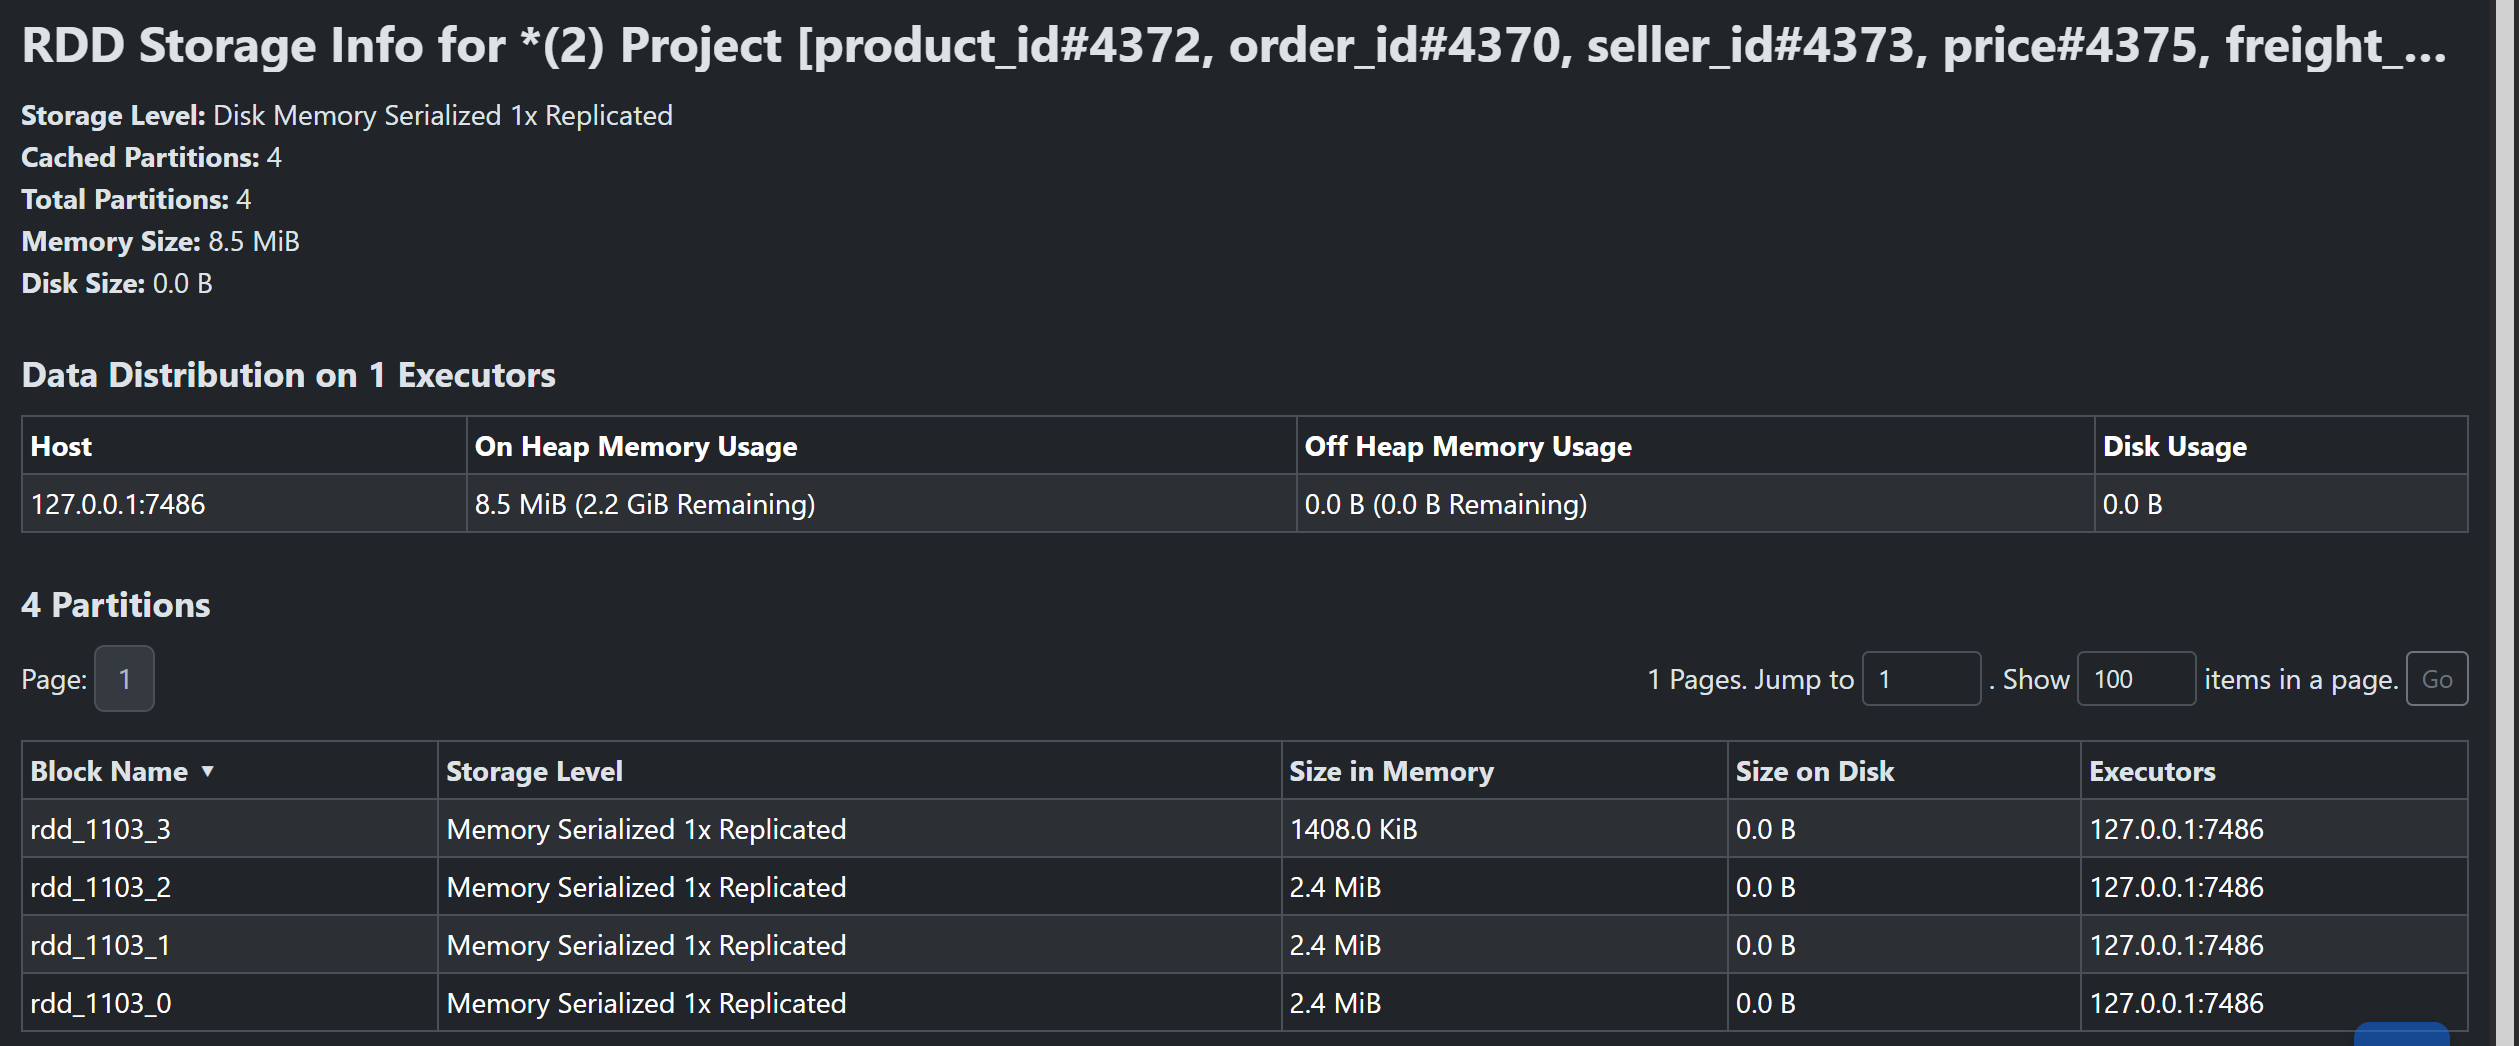

In [43]:
mart_cached.unpersist(blocking=True)
print("После unpersist:", mart_cached.is_cached)
table_d_cache = pd.DataFrame([
    {"Вариант": "Без persist", "Материализация, с": "-", "Action 1, с": round(nc_a1, 3), "Action 2, с": round(nc_a2, 3),
     "Итого на 2 действия, с": round(nc_a1 + nc_a2, 3)},
    {"Вариант": "MEMORY_AND_DISK", "Материализация, с": round(t_mat, 3), "Action 1, с": round(c_a1, 3),
     "Action 2, с": round(c_a2, 3), "Итого на 2 действия, с": round(t_mat + c_a1 + c_a2, 3)},
])
table_d_cache

После unpersist: False


,Вариант,"Материализация, с","Action 1, с","Action 2, с","Итого на 2 действия, с"
0,Без persist,—,0.204,0.201,0.406
1,MEMORY_AND_DISK,0.457,0.111,0.126,0.694


**Вывод:** без кэша медианы двух действий - 0.204 и 0.201 с (всего 0.405 с). С `persist(MEMORY_AND_DISK)` материализация заняла 0.457 с,
а действия - 0.111 и 0.126 с. Аналогично учебной части ускорение Action не позволило ускорить процесс целиком из-за длительной операции материализации.
Во вкладке Storage - витрина уровня MEMORY_AND_DISK: 4 партиции, 8.46 Мб в памяти, на диск ничего не вытеснено.

### 14.7. Серия по числу партиций
Витрина раскладывается на p партиций и кэшируется заранее, чтобы в замер попадала только агрегация по категории над p входными партициями.
Для каждого p - 3 повтора, итог - медиана.

In [44]:
sc.setJobGroup("D_BENCH", "Вариант D: серия по числу партиций", interruptOnCancel=True)
spark.conf.set("spark.sql.shuffle.partitions", "8")
D_P_VALUES = [1, 2, 4, 8, 16, 32]

def d_query(df):
    return (df.groupBy("product_category_name")
              .agg(F.sum("gross_value").alias("g"), F.avg("freight_share").alias("fs"))
              .agg(F.sum("g")).first()[0])

d_bench = []
for p in D_P_VALUES:
    df_p = items_mart.repartition(p).persist(StorageLevel.MEMORY_AND_DISK)
    df_p.count()                               # материализация вне замера
    d_query(df_p)                              # прогрев
    times = []
    for _ in range(3):
        t0 = perf_counter(); d_query(df_p); times.append(perf_counter() - t0)
    df_p.unpersist(blocking=True)
    d_bench.append((p, *times, median(times)))
    print(p, [round(t, 3) for t in times], round(median(times), 3))

table_d_bench = pd.DataFrame(d_bench, columns=["p", "Run 1, с", "Run 2, с", "Run 3, с", "Median, с"])
table_d_bench["S(p)=T(1)/T(p)"] = table_d_bench["Median, с"].iloc[0] / table_d_bench["Median, с"]
table_d_bench.round(3)

1 [0.08, 0.079, 0.059] 0.079
2 [0.095, 0.127, 0.11] 0.11
4 [0.092, 0.113, 0.096] 0.096
8 [0.142, 0.112, 0.101] 0.112
16 [0.19, 0.175, 0.159] 0.175
32 [0.227, 0.24, 0.224] 0.227


,p,"Run 1, с","Run 2, с","Run 3, с","Median, с",S(p)=T(1)/T(p)
0,1,0.080,0.079,0.059,0.079,1.000
1,2,0.095,0.127,0.110,0.110,0.716
2,4,0.092,0.113,0.096,0.096,0.823
3,8,0.142,0.112,0.101,0.112,0.705
4,16,0.190,0.175,0.159,0.175,0.452
5,32,0.227,0.240,0.224,0.227,0.348


**Вывод:** лучшее время при p = 1 (медиана 0.079 с), на втором месте p = 4 (0.096 с). Дальше медиана растёт: 0,112 с при p = 8, 0.175 с при p = 16 и 0.227 с при p = 32, то есть почти в 3 раза дольше, чем при p = 1 (S(32) = 0.35).
В отличие от `spark.range`, где оптимум оказался при p = 4, здесь даже 2–4 партиции не дают выигрыша. Витрина в кэше занимает около 8 MiB, агрегация по 73 категориям выполняется за миллисекунды, поэтому время определяют накладные расходы на создание задач и shuffle (каждая партиция даёт свои частичные итоги по всем категориям), а не вычисления.

### 14.8. Запись итоговой витрины с разным числом партиций

In [45]:
sc.setJobGroup("D_FILES", "Вариант D: запись витрины", interruptOnCancel=True)
table_d_files = pd.DataFrame([write_and_measure(items_mart, p, prefix="mart_p") for p in [1, 8, 32]])
table_d_files

,p,part-файлов,"Общий размер, MiB","Средний файл, KiB","Время записи, с"
0,1,1,6.269,6419.5,0.866
1,8,8,8.155,1043.8,0.515
2,32,32,9.818,314.2,0.968


**Вывод:** число part-файлов совпало с числом партиций (1, 8, 32). Средний файл уменьшился с 6420 Кб до 314 Кб, а общий объём вырос с 6.27 до 9.82 Мб из-за метаданных каждого файла и худшего сжатия. Запись 32 файлов заняла 0.968 с против 0.866 и 0.515 с для 1 и 8 файлов. Для витрины такого размера лучший вариант - 8 партиций

### 14.9. Журнал Spark UI по самостоятельной части

In [46]:
journal_d = pd.DataFrame([
    journal_row("D: lazy + count()", d_lazy, "Job появился только после Action"),
    journal_row("D: groupBy category", d_groupby, "Exchange hashpartitioning(product_category_name, 8)"),
    journal_row("D: Sort Merge Join (3 запуска)", d_smj_info, "Exchange + Sort с обеих сторон"),
    journal_row("D: Broadcast Hash Join (3 запуска)", d_bhj_info, "broadcast products, без shuffle большой стороны"),
    journal_row("D: persist + повторные действия", d_persist, "повторные действия читают кэш (InMemoryTableScan)"),
])
journal_d

,Эксперимент,Jobs,Stages (выполнено / пропущено),Tasks по стадиям,"Shuffle Write, KiB","Shuffle Read, KiB",Что подтверждает UI
0,D: lazy + count(),1,2 / 0,4 - 1,0.2,0.2,Job появился только после Action
1,D: groupBy category,2,4 / 0,1 - 4 - 8 - 8,6087.1,6087.1,Exchange hashpartitioning(product_category_nam...
2,D: Sort Merge Join (3 запуска),3,12 / 0,1 - 4 - 8 - 1 - 4 - 1 - 8 - 1 - 4 - 1 - 8 - 1,11498.7,11498.7,Exchange + Sort с обеих сторон
3,D: Broadcast Hash Join (3 запуска),6,9 / 0,1 - 4 - 1 - 1 - 4 - 1 - 1 - 4 - 1,0.6,0.6,"broadcast products, без shuffle большой стороны"
4,D: persist + повторные действия,8,21 / 0,1 - 4 - 1 - 4 - 8 - 1 - 4 - 8 - 1 - 4 - 8 - 1 ...,42.5,42.5,повторные действия читают кэш (InMemoryTableScan)


## 15. Итоговые выводы и ограничения

**Выводы по самостоятельной части:**
1. **Lazy evaluation.** Цепочка из четырёх преобразований над order_items построена за 102.8 мс без Jobs; единственный Job появился только на `count()` (0.318 с).
2. **repartition и coalesce.** На ключе product_category_name repartition(4) ценой полного shuffle выровнял партиции (max/mean = 1.00), coalesce(4) обошёлся без нового Exchange,
   но сохранил разброс (1.25). Перекос по категориям мягче, чем по штатам в учебной части (2.45 против 5.59).
3. **Shuffle при groupBy.** `countDistinct(order_id)` превратил агрегацию в двухуровневую и дал 6 Мб shuffle - почти в 14 раз больше, чем простая агрегация по продавцам в учебной части (438.6 Кб).
4. **Стратегии JOIN.** Sort Merge Join перемешивал 3.8 Мб за запуск, Broadcast Hash Join - нет; по медиане трёх запусков BHJ оказался быстрее (0.139 против 0.191 с), что совпадает с результатом учебной части. Преимущество условное: справочник products мал, а абсолютная разница составляет сотые доли секунды.
5. **persist.** Витрина, используемая двумя действиями, как и в учебной части не окупила кэш: 0.694 с с учётом материализации против 0.406 с без кэша.
6. **Число партиций.** Для 112 тыс. строк в кэше оптимум p = 1 (0.079 с); рост до 32 партиций замедлил агрегацию почти в 3 раза (0.227 с) - на 20 CPU накладные расходы на задачи перевешивают параллелизм.
7. **Маленькие файлы.** 32 партиции дали 32 файла по 314 Кб и на 57% больший объём, чем один файл.

**Ограничения измерений:**
1. **Зависимость от стенда.** Время зависит от CPU, памяти, фоновых процессов и прогрева JVM и не переносится на другие компьютеры; сравнивать можно только варианты внутри одной сессии.
2. **Локальный режим.** `local[*]` выполняет все задачи в одном процессе: сетевого обмена при shuffle и broadcast нет, поэтому на кластере разница между стратегиями может быть больше.
3. **Малый объём данных.** Наборы небольшие (100 тыс. – 1 млн строк), поэтому многие различия сопоставимы с накладными расходами планировщика.
4. **Шум замеров.** Первые запуски заметно медленнее следующих из-за прогрева JVM (у Sort Merge Join 0.386 с против 0.184–0.191 с, при q = 2 - 0.198 с против 0.069–0.103 с), а многие различия между вариантами составляют сотые доли секунды. Поэтому выводы строились по медиане, но трёх повторов мало для надёжной статистики.

In [47]:
spark.stop()